# Preparation et exploration des données

In [56]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

%matplotlib inline

import logging
from datetime import date,datetime
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import numpy as np
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import langid
from py3langid.langid import LanguageIdentifier, MODEL_FILE
from collections import Counter

import torch
from transformers import BertTokenizer, BertModel
from tqdm import tqdm
import html as html_lib
from wordcloud import WordCloud


In [57]:
FIGURES_DIR = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIGURES_DIR, name)
    plt.savefig(path, bbox_inches='tight', dpi=150)
    print(f"Figure sauvegardée : {path}")


In [58]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

### Chargement des données

In [59]:

X_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\X_train_update.csv",sep=",", encoding="utf-8", index_col=0)
y_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\Y_train.csv",sep=",", encoding="utf-8", index_col=0)
# liste des chemins d'accès aux images

data_train = pd.concat([X_train, y_train], axis=1)

images_path = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train"
image_names = [name for name in os.listdir(images_path)]
print(f"Nombre d'images : {len(image_names)}\nExemple de nom d'image : {image_names[0]}\n")


Nombre d'images : 84916
Exemple de nom d'image : image_1000076039_product_580161.jpg



In [60]:
# Création d'un DataFrame pour les images avec les ids extraits des noms de fichiers
image_list = []
regex = re.compile(r'image_(\d+)_product_(\d+)\.jpg')
for name in image_names:
    match = regex.match(name)
    if match:
        img_id = int(match.group(1))
        product_id = int(match.group(2))
        image_list.append({
            'image_name': name,
            'imageid': int(match.group(1)),
            'productid': int(match.group(2))
        })

image_df = pd.DataFrame(image_list)
print(image_df.head(10))
print(f"\nNombre d'images dans image_df : {len(image_df)} comparé au nombre dans la liste de base {len(image_names)}")

                               image_name     imageid  productid
0     image_1000076039_product_580161.jpg  1000076039     580161
1  image_1000089455_product_348990858.jpg  1000089455  348990858
2  image_1000092894_product_353108104.jpg  1000092894  353108104
3  image_1000093804_product_343306951.jpg  1000093804  343306951
4  image_1000095646_product_344209267.jpg  1000095646  344209267
5  image_1000095647_product_148177050.jpg  1000095647  148177050
6  image_1000099971_product_352683003.jpg  1000099971  352683003
7  image_1000100220_product_352601770.jpg  1000100220  352601770
8  image_1000222973_product_351172420.jpg  1000222973  351172420
9  image_1000228891_product_355017693.jpg  1000228891  355017693

Nombre d'images dans image_df : 84916 comparé au nombre dans la liste de base 84916


In [61]:
data_train = pd.merge(data_train,image_df,on=['productid', 'imageid'],how='left')
data_train["designation"] = data_train["designation"].str.lower()
data_train["description"] = data_train["description"].str.lower()

In [62]:
CLASS_NAMES = {
    10:   "Livres d'occasion",
    40:   "Jeux vidéo",
    50:   "Accessoires gaming",
    60:   "Consoles de jeux",
    1140: "Figurines",
    1160: "Cartes de collection",
    1180: "Figurines / Jeux de rôle",
    1280: "Jouets enfants",
    1281: "Jeux de société",
    1300: "Modélisme",
    1301: "Vêtements / Équipements sport",
    1302: "Jeux d'extérieur",
    1320: "Puériculture",
    1560: "Mobilier",
    1920: "Literie",
    1940: "Alimentation",
    2060: "Décoration / Luminaires",
    2220: "Animalerie",
    2280: "Journaux / Revues",
    2403: "Livres / BD",
    2462: "Jeux PC (dématérialisés)",
    2522: "Fournitures de bureau",
    2582: "Mobilier de jardin",
    2583: "Piscines / Spas",
    2585: "Jardinage",
    2705: "Livres",
    2905: "Jeux / Puzzles",
}

data_train['class_name'] = data_train['prdtypecode'].map(CLASS_NAMES)
print(data_train[['prdtypecode', 'class_name']].drop_duplicates().sort_values('prdtypecode').to_string(index=False))

 prdtypecode                    class_name
          10             Livres d'occasion
          40                    Jeux vidéo
          50            Accessoires gaming
          60              Consoles de jeux
        1140                     Figurines
        1160          Cartes de collection
        1180      Figurines / Jeux de rôle
        1280                Jouets enfants
        1281               Jeux de société
        1300                     Modélisme
        1301 Vêtements / Équipements sport
        1302              Jeux d'extérieur
        1320                  Puériculture
        1560                      Mobilier
        1920                       Literie
        1940                  Alimentation
        2060       Décoration / Luminaires
        2220                    Animalerie
        2280             Journaux / Revues
        2403                   Livres / BD
        2462      Jeux PC (dématérialisés)
        2522         Fournitures de bureau
        258

In [63]:
print(data_train.head())

                                         designation  \
0  olivia: personalisiertes notizbuch / 150 seite...   
1  journal des arts (le) n° 133 du 28/09/2001 - l...   
2  grand stylet ergonomique bleu gamepad nintendo...   
3  peluche donald - europe - disneyland 2000 (mar...   
4                               la guerre des tuques   

                                         description   productid     imageid  \
0                                                NaN  3804725264  1263597046   
1                                                NaN   436067568  1008141237   
2  pilot style touch pen de marque speedlink est ...   201115110   938777978   
3                                                NaN    50418756   457047496   
4  luc a des id&eacute;es de grandeur. il veut or...   278535884  1077757786   

   prdtypecode                               image_name          class_name  
0           10  image_1263597046_product_3804725264.jpg   Livres d'occasion  
1         2280   image_100

In [64]:
print('Informations générales:')
print(f'Lignes   : {len(data_train):,}')
print(f'Colonnes : {list(data_train.columns)}')
print(f'Classes  : {data_train["prdtypecode"].nunique()}')
print()
print('Valeurs manquantes:')
missing = data_train.isna().sum()
pct     = data_train.isna().sum()/len(data_train) * 100
pd.DataFrame({'nombre_NaN': missing, 'poucentage_NaN': pct.round(2)})

Informations générales:
Lignes   : 84,916
Colonnes : ['designation', 'description', 'productid', 'imageid', 'prdtypecode', 'image_name', 'class_name']
Classes  : 27

Valeurs manquantes:


,nombre_NaN,poucentage_NaN
designation,0,0.00
description,29800,35.09
productid,0,0.00
imageid,0,0.00
prdtypecode,0,0.00
image_name,0,0.00
class_name,0,0.00


In [65]:
print('Doublons:')
print(f'Lignes dupliquées (productid) : {data_train["productid"].duplicated().sum()}')
print(f'Lignes dupliquées (imageid)   : {data_train["imageid"].duplicated().sum()}')

Doublons:
Lignes dupliquées (productid) : 0
Lignes dupliquées (imageid)   : 0


### Repartition des classes

class_name
Piscines / Spas            10209
Mobilier                    5073
Modélisme                   5045
Décoration / Luminaires     4993
Fournitures de bureau       4989
Name: count, dtype: int64


C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\2569310311.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax1, palette='Blues_r', legend=False, order=class_counts.index)
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\2569310311.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\2569310311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pct_class.index, y=pct_class.values, ax=ax2, palette='Blues_r', legend=False,order=class_co

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\01_class_distribution.png


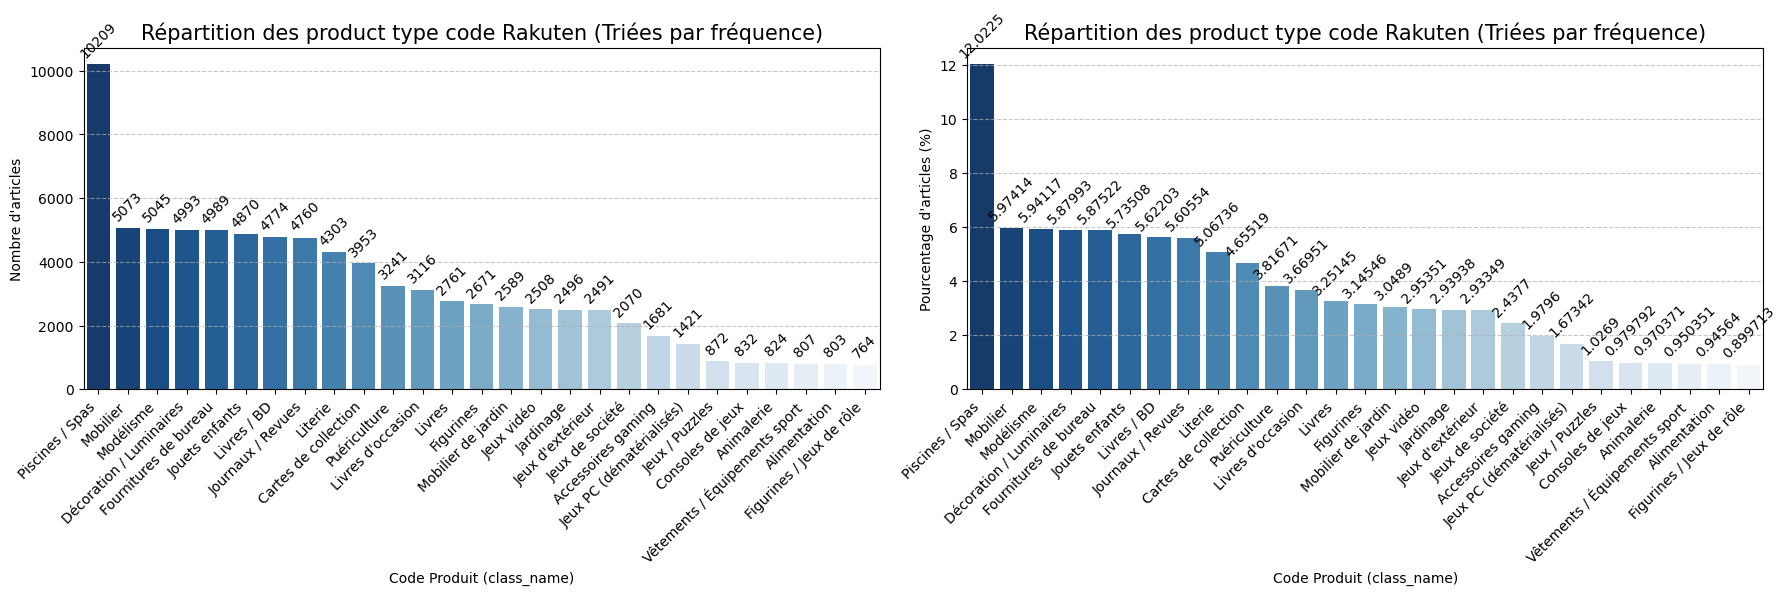

In [66]:
class_counts = data_train['class_name'].value_counts()
pct_class = class_counts / len(data_train) * 100

print(class_counts.head(5))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax1, palette='Blues_r', legend=False, order=class_counts.index)
for container in ax1.containers:
    ax1.bar_label(container, padding=3, fontsize=10, rotation=45)
ax1.set_title('Répartition des product type code Rakuten (Triées par fréquence)', fontsize=15)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.set_xlabel('Code Produit (class_name)')
ax1.set_ylabel('Nombre d\'articles')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

sns.barplot(x=pct_class.index, y=pct_class.values, ax=ax2, palette='Blues_r', legend=False,order=class_counts.index)
for container in ax2.containers:
    ax2.bar_label(container, padding=3, fontsize=10, rotation=45)
ax2.set_title('Répartition des product type code Rakuten (Triées par fréquence)', fontsize=15)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
ax2.set_xlabel('Code Produit (class_name)')
ax2.set_ylabel('Pourcentage d\'articles (%)')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
save_fig("01_class_distribution.png")
plt.show()


#### Analyse — Déséquilibre des classes (Graph 1)

Le dataset présente un **déséquilibre marqué** : la classe *Piscines / Spas* concentre ~12% des produits tandis que *Figurines / Jeux de rôle* n'en représente que ~0,9%.

**Constat métier** : Rakuten est une marketplace généraliste mais dont le catalogue est fortement orienté vers les produits de loisir intérieur (mobilier, décoration, puériculture). Les catégories gaming de niche (consoles, jeux PC dématérialisés) sont sous-représentées, probablement parce que ces produits sont davantage vendus sur des plateformes spécialisées.

**Impact modélisation** : Il faudra recourir à du **class weighting** ou du **sur-échantillonnage** (SMOTE ou augmentation de données) lors de l'entraînement.

**Validation statistique** : test du Chi² d'uniformité sur la distribution des classes.


In [67]:
from scipy.stats import chisquare

observed = class_counts.values
expected = np.full(len(observed), observed.sum() / len(observed))  # distribution uniforme

chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)
ratio_max_min = observed.max() / observed.min()

print("Test Chi² — Uniformité de la distribution des classes")
print(f"Chi²     : {chi2_stat:,.1f}")
print(f"p-value  : {p_value:.2e}")
print(f"Ratio max/min : {ratio_max_min:.1f}x")
print()
if p_value < 0.05:
    print("la distribution des classes N'est PAS uniforme (p < 0.05).")
    print(f"  La classe la plus représentée ({class_counts.index[0]}) a {ratio_max_min:.1f}x plus "
          f"de produits que la moins représentée ({class_counts.index[-1]}).")


Test Chi² — Uniformité de la distribution des classes
Chi²     : 36,570.3
p-value  : 0.00e+00
Ratio max/min : 13.4x

la distribution des classes N'est PAS uniforme (p < 0.05).
  La classe la plus représentée (Piscines / Spas) a 13.4x plus de produits que la moins représentée (Figurines / Jeux de rôle).


Top 5 classes les plus fréquentes:
class_name
Piscines / Spas            10209
Mobilier                    5073
Modélisme                   5045
Décoration / Luminaires     4993
Fournitures de bureau       4989

Top 5 classes les moins fréquentes:
class_name
Consoles de jeux                 832
Animalerie                       824
Vêtements / Équipements sport    807
Alimentation                     803
Figurines / Jeux de rôle         764
Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\01b_class_donut.png


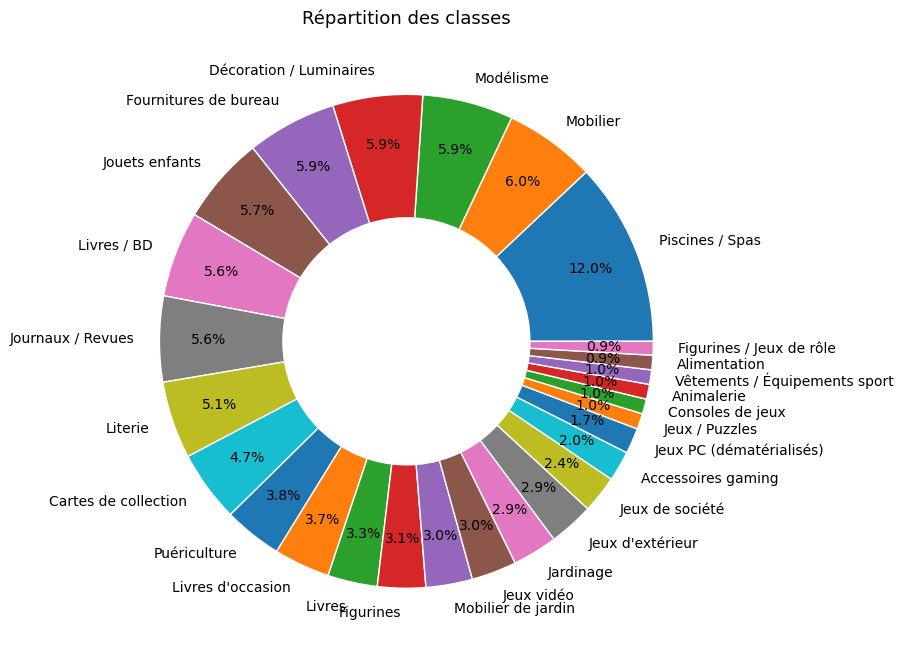

In [68]:
print('Top 5 classes les plus fréquentes:')
print(class_counts.head(5).to_string())
print()
print('Top 5 classes les moins fréquentes:')
print(class_counts.tail(5).to_string())

# Donut chart
fig, ax = plt.subplots(figsize=(9, 9))
wedge_props = dict(width=0.5, edgecolor='white')
ax.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
       pctdistance=0.8, wedgeprops=wedge_props)
ax.set_title('Répartition des classes', fontsize=13)
plt.tight_layout()
save_fig("01b_class_donut.png")
plt.show()


### Nettoyage des HTML Patterns

In [69]:
html_entity_pattern = re.compile(r'&[a-zA-Z]+;|&#\d+;')
html_tag_pattern    = re.compile(r'<[^>]+>', re.IGNORECASE)

mask_desig = data_train['designation'].str.contains(html_entity_pattern, na=False)
mask_desc  = data_train['description'].str.contains(html_entity_pattern, na=False)
print(f'Avant — entités HTML dans désignation : {mask_desig.sum():,} ({mask_desig.mean()*100:.1f}%)')
print(f'Avant — entités HTML dans description : {mask_desc.sum():,}  ({mask_desc.mean()*100:.1f}%)')
print()
print('Exemples avant nettoyage :')
display(data_train[mask_desc]['description'].dropna().head(5).to_frame())

# Nettoyage : 1) unescape entités  2) suppression balises
def clean_html(text):
    if not isinstance(text, str):
        return text
    text = html_lib.unescape(text)            # &amp; → &,  &eacute; → é
    text = html_lib.unescape(text)            # double passe pour les entités imbriquées
    text = html_tag_pattern.sub(' ', text)    # <br />, </li>, <BR /> → espace
    text = re.sub(r'\s+', ' ', text).strip() # espaces multiples → un seul
    return text

data_train['designation'] = data_train['designation'].apply(clean_html)
data_train['description'] = data_train['description'].apply(clean_html)

still_d = data_train['designation'].str.contains(html_entity_pattern, na=False).sum()
still_s = data_train['description'].str.contains(html_entity_pattern, na=False).sum()
tag_d   = data_train['designation'].str.contains(html_tag_pattern, na=False).sum()
tag_s   = data_train['description'].str.contains(html_tag_pattern, na=False).sum()
print(f'\nAprès — entités restantes  — désignation : {still_d}  |  description : {still_s}')
print(f'Après — balises restantes  — désignation : {tag_d}    |  description : {tag_s}')

display(data_train[mask_desc]['description'].dropna().head(5).to_frame())


Avant — entités HTML dans désignation : 989 (1.2%)
Avant — entités HTML dans description : 35,030  (41.3%)

Exemples avant nettoyage :


,description
4,luc a des id&eacute;es de grandeur. il veut or...
9,tente pliante v3s5 pro pvc 500 gr/m² - 3 x 4m5...
11,canapé et fauteuil chesterfield en cuir antiqu...
13,paire de voilages droits fantaisie qui mettra ...
14,matelas:<br />â· accueil : ferme .<br />â· sou...



Après — entités restantes  — désignation : 0  |  description : 0
Après — balises restantes  — désignation : 0    |  description : 0


,description
4,luc a des idées de grandeur. il veut organiser...
9,tente pliante v3s5 pro pvc 500 gr/m² - 3 x 4m5...
11,canapé et fauteuil chesterfield en cuir antiqu...
13,paire de voilages droits fantaisie qui mettra ...
14,matelas: â· accueil : ferme . â· soutien : trè...


### Detection langue


In [70]:
identifier = LanguageIdentifier.from_pickled_model(MODEL_FILE,norm_probs=True)  #https://github.com/adbar/py3langid
identifier.set_languages(['fr', 'en', 'es', 'de'])

def detect_lang(text, identifier):
    if pd.isna(text) or len(str(text)) < 5:
        return 'unknown'
    
    lang, prob = identifier.classify(str(text))
    if prob < 0.8: # est ce que c'est trop ?
        return 'unknown'
    return lang

text = data_train['designation'] + ' ' + data_train['description'].fillna('')
data_train['language'] = text.apply(lambda x: detect_lang(x, identifier))

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\02_language_distribution.png


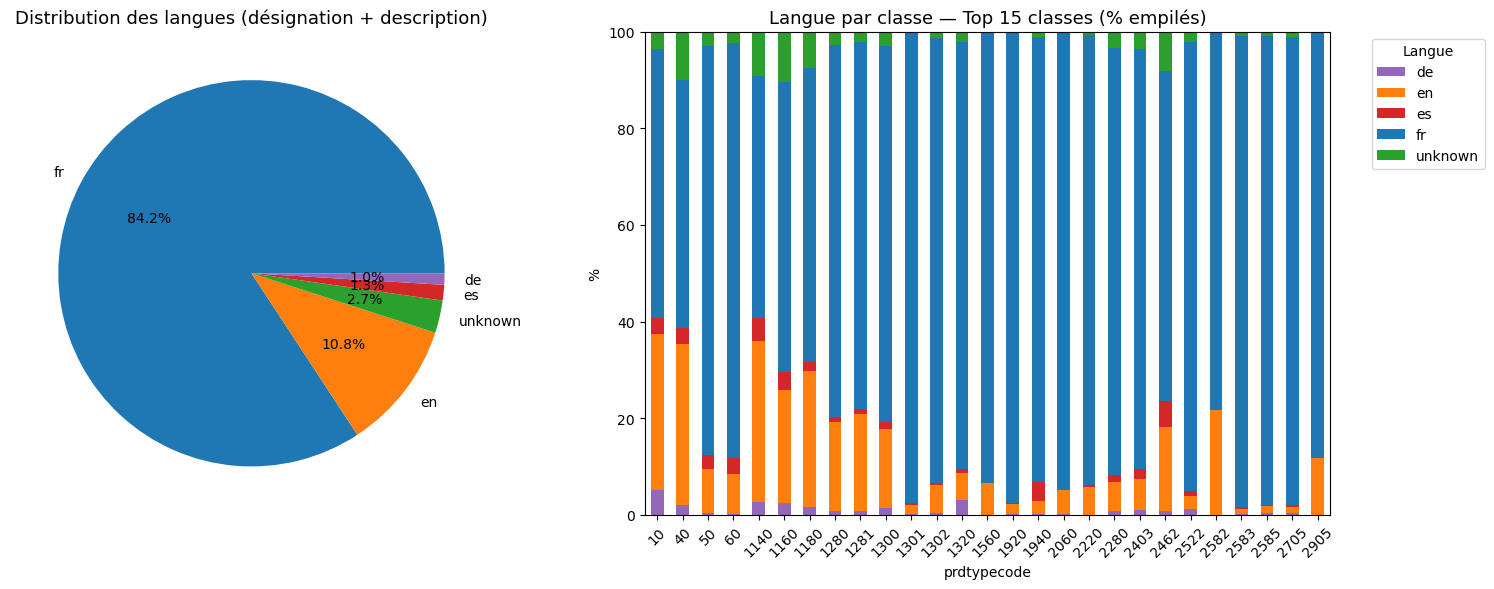

In [71]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

lang_counts = data_train['language'].value_counts()

# Palette commune basée sur toutes les langues présentes
langs = lang_counts.index.tolist()
colors = plt.cm.tab10.colors
lang_colors = {lang: colors[i % len(colors)] for i, lang in enumerate(langs)}

# Pie avec les couleurs dans l'ordre de lang_counts
ax1.pie(lang_counts.values,
        labels=lang_counts.index,
        autopct='%1.1f%%',
        colors=[lang_colors[l] for l in lang_counts.index])
ax1.set_title('Distribution des langues (désignation + description)', fontsize=13)

top = data_train['prdtypecode'].value_counts().index
lang_class = (data_train[data_train['prdtypecode'].isin(top)]
              .groupby(['prdtypecode', 'language'])
              .size().unstack(fill_value=0))
lang_class_pct = lang_class.div(lang_class.sum(axis=1), axis=0) * 100

# Bar avec les mêmes couleurs dans l'ordre des colonnes
lang_class_pct.plot(kind='bar', stacked=True, ax=ax2,
                    color=[lang_colors[l] for l in lang_class_pct.columns])
ax2.set_title('Langue par classe — Top 15 classes (% empilés)', fontsize=13)
ax2.set_xlabel('prdtypecode')
ax2.set_ylabel('%')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Langue', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
save_fig("02_language_distribution.png")
plt.show()


#### Analyse — Distribution des langues (Graph 2)

La majorité des produits (~80%) est en **français**, ce qui est cohérent avec la plateforme Rakuten France. Cependant, une proportion non négligeable de produits est en **anglais**, **allemand** ou **espagnol**, et une partie reste classifiée `unknown` (texte trop court ou mixte).

**Constat métier** : Les produits gaming (cartes de collection, jeux PC) sont davantage en anglais car les éditeurs commercialisent souvent des produits avec des titres anglophones en Europe. Les livres et revues sont quasi-exclusivement en français. Cette hétérogénéité linguistique est un **biais du dataset** : un modèle doit être robuste aux langues mixtes plutôt qu'assumer un corpus monolingue.

**Impact modélisation** : l'utilisation d'un tokenizer multilingue (mBERT, XLM-R) sera préférable à un modèle français uniquement (CamemBERT).

**Validation statistique** : test Chi² d'indépendance entre langue et classe.


In [72]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(data_train['prdtypecode'], data_train['language'])
chi2, p, dof, expected_ct = chi2_contingency(contingency)

print("=== Test Chi² — Indépendance langue × classe ===")
print(f"Chi²    : {chi2:,.1f}")
print(f"p-value : {p:.2e}")
print(f"ddl     : {dof}")
print()
if p < 0.05:
    print("✓ Rejet de H0 : la langue N'est PAS indépendante de la classe (p < 0.05).")
    print("  Certaines classes ont une composition linguistique significativement différente.")
    print()
# Cramér's V pour mesurer la force de l'association
n = contingency.values.sum()
min_dim = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V : {cramers_v:.3f}  (0=aucune association, 1=association parfaite)")


=== Test Chi² — Indépendance langue × classe ===
Chi²    : 15,283.5
p-value : 0.00e+00
ddl     : 104

✓ Rejet de H0 : la langue N'est PAS indépendante de la classe (p < 0.05).
  Certaines classes ont une composition linguistique significativement différente.

Cramér's V : 0.212  (0=aucune association, 1=association parfaite)


In [73]:
print(data_train[data_train['language'] == 'de']['designation'].head(20))

0       olivia: personalisiertes notizbuch / 150 seite...
6              christof e: bildungsprozessen auf der spur
131       dr. mercurius' heilsame reise zum planeten erde
155     scott mitchell - cincinnati bengals - 2001 upp...
382     zöllner schlafsack mit applikation sternchen b...
396         les schtroumpfs - schtroumpf toothbrush 20064
449         army men in space jeu pc big box grosse boite
460                             ich du und die ganze welt
513                  sherwood g: pedigree register vol. 2
571                     collier - zelda - charm windwaker
585           beach toys la reine des neiges - kick board
675     vinyles 33t--coffret 4lp--richard wagner : tan...
683     dahle tableau blanc slim board basic ft 60 x 9...
760                  vw golf variant schabak 1/43-schabak
793                               spa beausoleil 6 places
809     magic mtg - commander 2013 - sek'kuar gardemor...
819     piscine à balles - aire de jeu enfants - avec ...
923     carte 

### Longueur texte

Longueur DÉSIGNATION:
count    84916.0
mean        11.6
std          6.2
min          3.0
25%          7.0
50%         11.0
75%         14.0
max         56.0
Name: len_desig, dtype: float64

Longueur DESCRIPTION (avec-NaN):
count    84916.0
mean        79.5
std        114.5
min          0.0
25%          0.0
50%         35.0
75%        124.0
max       2068.0
Name: len_desc, dtype: float64


C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\377888684.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1][0].set_xticklabels(axes[1][0].get_xticklabels(), rotation=45, ha='right')
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\377888684.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1][1].set_xticklabels(axes[1][1].get_xticklabels(), rotation=45, ha='right')


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\03_text_lengths.png


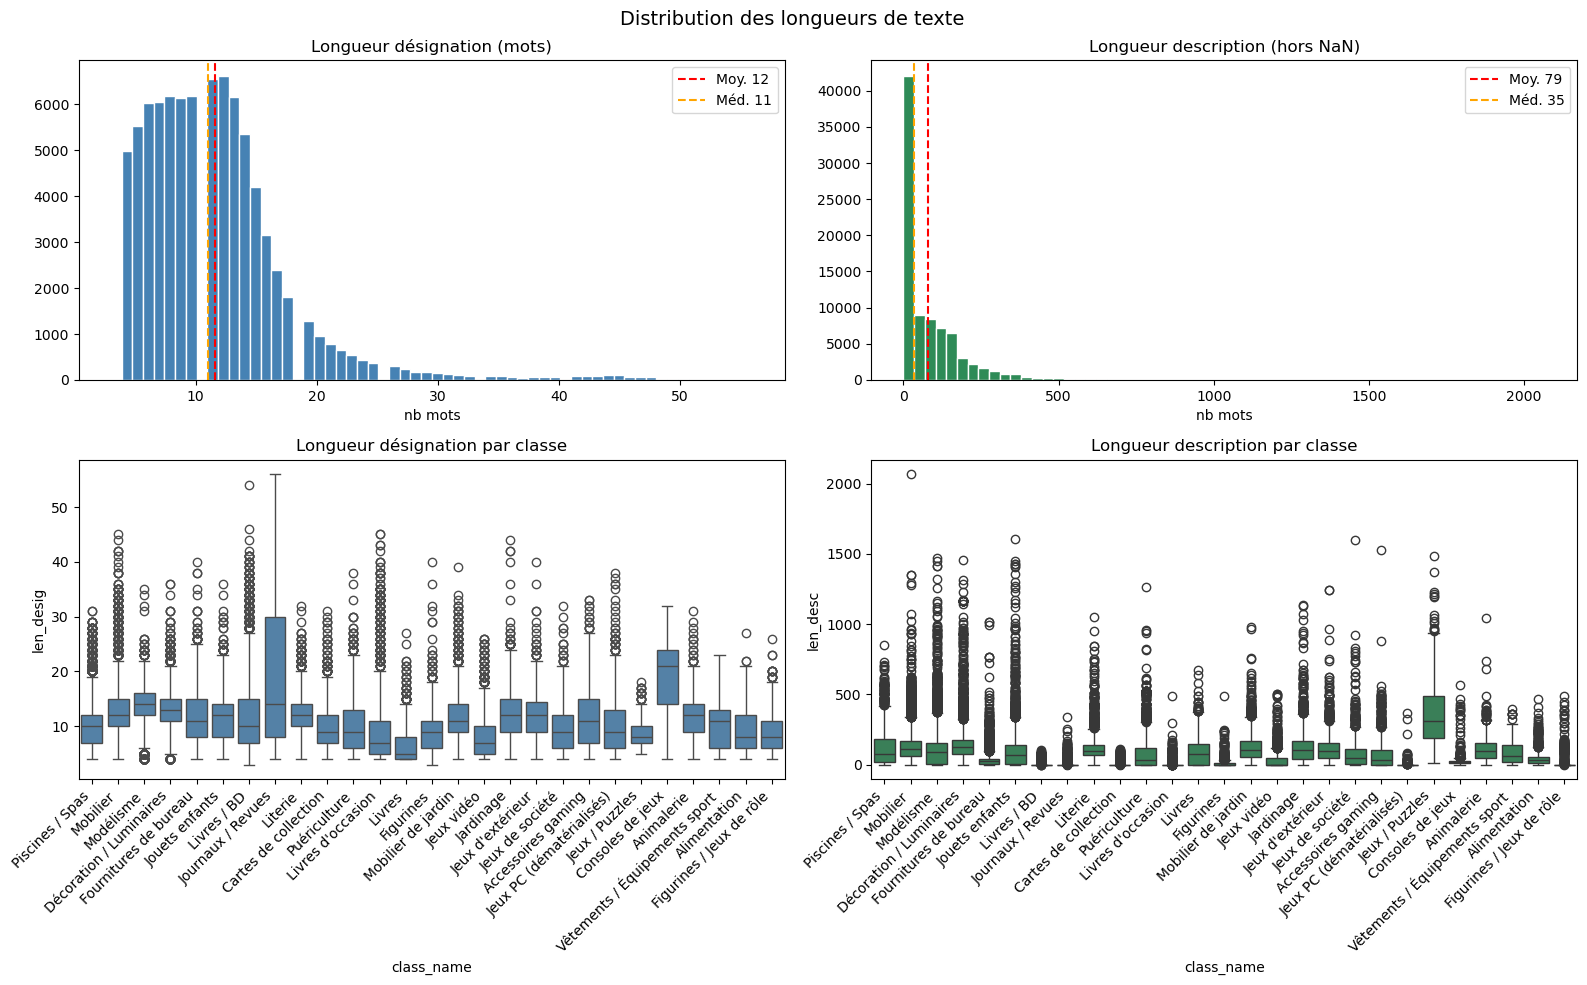

In [74]:
data_train['len_desig'] = data_train['designation'].str.split().str.len().fillna(0).astype(int)
data_train['len_desc']  = data_train['description'].str.split().str.len().fillna(0).astype(int)

print('Longueur DÉSIGNATION:')
print(data_train['len_desig'].describe().round(1))
print()
print('Longueur DESCRIPTION (avec-NaN):')
print(data_train['len_desc'].describe().round(1))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0][0].hist(data_train['len_desig'], bins=60, color='steelblue', edgecolor='white')
axes[0][0].axvline(data_train['len_desig'].mean(), color='red', linestyle='--',
               label=f'Moy. {data_train["len_desig"].mean():.0f}')
axes[0][0].axvline(data_train['len_desig'].median(), color='orange', linestyle='--',
               label=f'Méd. {data_train["len_desig"].median():.0f}')
axes[0][0].set_title('Longueur désignation (mots)', fontsize=12)
axes[0][0].set_xlabel('nb mots')
axes[0][0].legend()

axes[0][1].hist(data_train['len_desc'].dropna(), bins=60, color='seagreen', edgecolor='white')
axes[0][1].axvline(data_train['len_desc'].mean(), color='red', linestyle='--',
               label=f'Moy. {data_train["len_desc"].mean():.0f}')
axes[0][1].axvline(data_train['len_desc'].median(), color='orange', linestyle='--',
               label=f'Méd. {data_train["len_desc"].median():.0f}')
axes[0][1].set_title('Longueur description (hors NaN)', fontsize=12)
axes[0][1].set_xlabel('nb mots')
axes[0][1].legend()

sns.boxplot(data=data_train, x='class_name', y='len_desig', order=class_counts.index,
            ax=axes[1][0], color='steelblue')
axes[1][0].set_title('Longueur désignation par classe', fontsize=12)
axes[1][0].set_xticklabels(axes[1][0].get_xticklabels(), rotation=45, ha='right')

sns.boxplot(data=data_train, x='class_name', y='len_desc', order=class_counts.index,
            ax=axes[1][1], color='seagreen')
axes[1][1].set_title('Longueur description par classe', fontsize=12)
axes[1][1].set_xticklabels(axes[1][1].get_xticklabels(), rotation=45, ha='right')

plt.suptitle('Distribution des longueurs de texte', fontsize=14)
plt.tight_layout()
save_fig("03_text_lengths.png")
plt.show()


#### Analyse — Longueur des textes par classe (Graph 3)

Les désignations sont courtes (médiane ~8 mots) et relativement homogènes entre classes. En revanche, les descriptions présentent une **forte variabilité inter-classes** : les classes *Jeux / Puzzles* ou *Mobilier* ont des descriptions très longues (>80 mots en moyenne) tandis que *Livres / BD* ou *Cartes de collection* ont des descriptions quasi-vides (~1 mot).

**Constat métier** : les vendeurs de produits physiques (mobilier, jardinage) rédigent des descriptions détaillées pour convaincre l'acheteur, tandis que les revendeurs de livres et jeux de collection se contentent du titre, car le produit est identifiable par son titre ou son ISBN. Ce comportement de rédaction **différencie les classes de manière discriminante** : la longueur de description peut être une feature utile pour le modèle.

**Validation statistique** : test de Kruskal-Wallis (non-paramétrique) — les distributions de longueur sont-elles identiques entre classes ?


In [75]:
from scipy.stats import kruskal

groups_desig = [g['len_desig'].values for _, g in data_train.groupby('class_name')]
groups_desc  = [g['len_desc'].values  for _, g in data_train.groupby('class_name')]

kw_desig = kruskal(*groups_desig)
kw_desc  = kruskal(*groups_desc)

print("=== Test de Kruskal-Wallis — Longueur par classe ===")
print(f"Désignation : H={kw_desig.statistic:,.1f}, p={kw_desig.pvalue:.2e}")
print(f"Description : H={kw_desc.statistic:,.1f},  p={kw_desc.pvalue:.2e}")
print()
for name, res in [("Désignation", kw_desig), ("Description", kw_desc)]:
    if res.pvalue < 0.05:
        print(f"✓ {name} : les longueurs diffèrent significativement entre classes (p < 0.05).")
        print(f"  → La longueur du texte est une feature discriminante pour la classification.")


=== Test de Kruskal-Wallis — Longueur par classe ===
Désignation : H=13,792.7, p=0.00e+00
Description : H=40,292.5,  p=0.00e+00

✓ Désignation : les longueurs diffèrent significativement entre classes (p < 0.05).
  → La longueur du texte est une feature discriminante pour la classification.
✓ Description : les longueurs diffèrent significativement entre classes (p < 0.05).
  → La longueur du texte est une feature discriminante pour la classification.


### Analyse de la description (valeurs manquantes par classe)

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\04_missing_descriptions.png


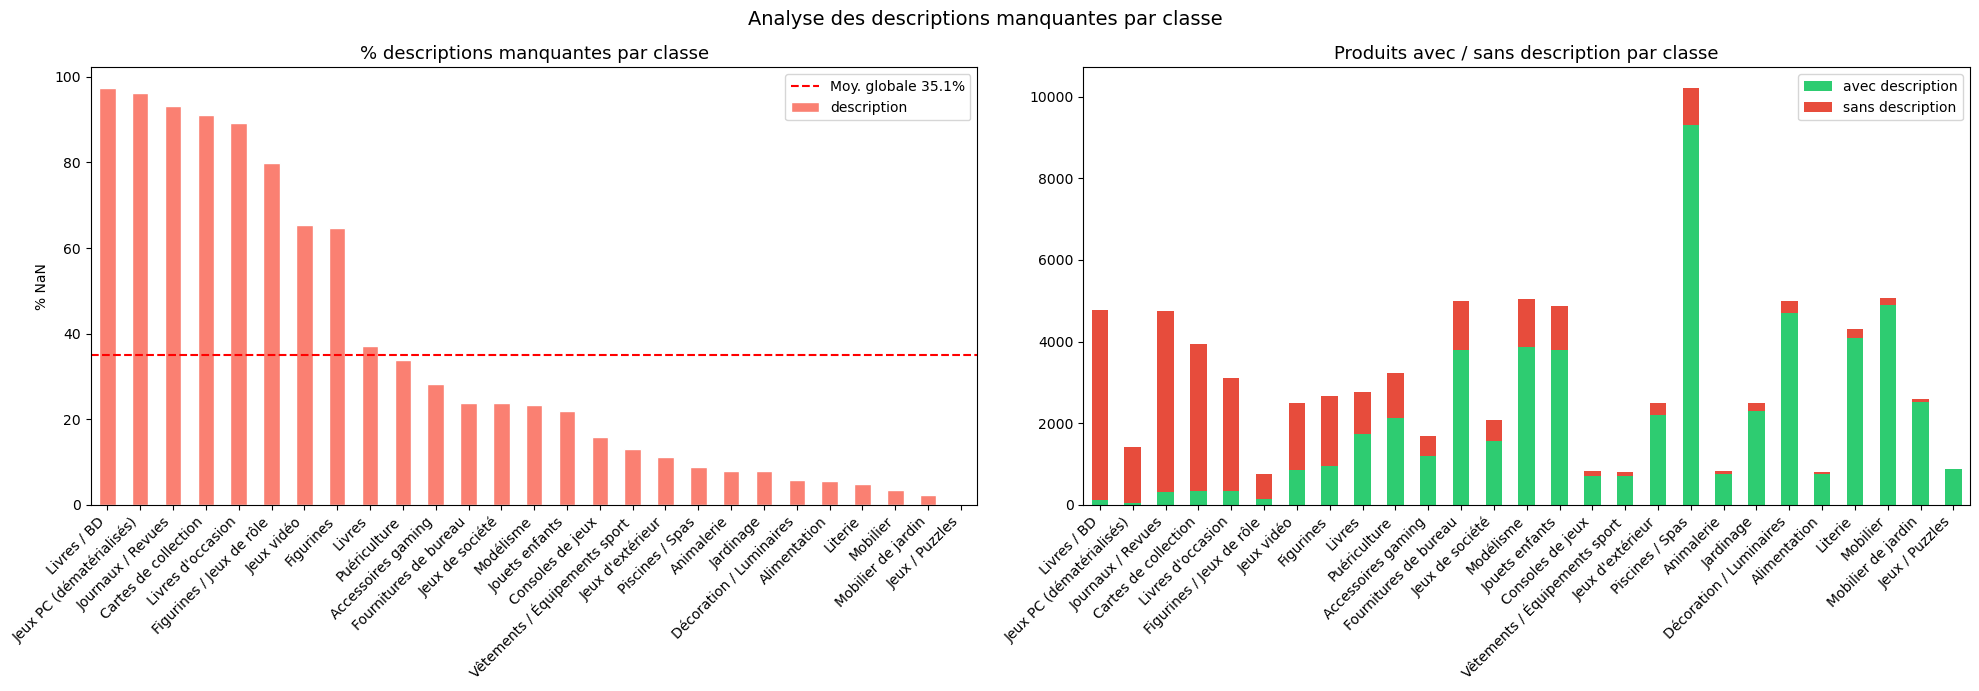


=== Tableau récapitulatif (trié par % manquant) ===
                               nb_produits  avec_desc  sans_desc  pct_manquant
class_name                                                                    
Livres / BD                            126        126       4648          97.4
Jeux PC (dématérialisés)                53         53       1368          96.3
Journaux / Revues                      320        320       4440          93.3
Cartes de collection                   349        349       3604          91.2
Livres d'occasion                      338        338       2778          89.2
Figurines / Jeux de rôle               153        153        611          80.0
Jeux vidéo                             866        866       1642          65.5
Figurines                              945        945       1726          64.6
Livres                                1736       1736       1025          37.1
Puériculture                          2140       2140       1101          34.0

In [76]:
nan_by_class = (data_train.groupby('class_name')['description']
                .apply(lambda x: x.isna().mean() * 100)
                .sort_values(ascending=False))

ordre = nan_by_class.index  

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

nan_by_class.plot(kind='bar', ax=axes[0], color='salmon', edgecolor='white')
axes[0].set_title('% descriptions manquantes par classe', fontsize=13)
axes[0].set_xlabel('')
axes[0].set_ylabel('% NaN')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].axhline(data_train['description'].isna().mean()*100, color='red',
                linestyle='--',
                label=f'Moy. globale {data_train["description"].isna().mean()*100:.1f}%')
axes[0].legend()

has_desc = (data_train.groupby('class_name')['description']
            .apply(lambda x: pd.Series({'avec': x.notna().sum(), 'sans': x.isna().sum()}))
            .unstack()
            .reindex(ordre))  

has_desc.plot(kind='bar', stacked=True, ax=axes[1], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Produits avec / sans description par classe', fontsize=13)
axes[1].set_xlabel('')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend(['avec description', 'sans description'])

plt.suptitle('Analyse des descriptions manquantes par classe', fontsize=14)
plt.tight_layout()
save_fig("04_missing_descriptions.png")
plt.show()

recap = data_train.groupby('class_name').agg(
    nb_produits  = ('description', 'count'),
    avec_desc    = ('description', lambda x: x.notna().sum()),
    sans_desc    = ('description', lambda x: x.isna().sum()),
    pct_manquant = ('description', lambda x: round(x.isna().mean() * 100, 1)),
).reindex(ordre)

print('\n=== Tableau récapitulatif (trié par % manquant) ===')
print(recap.to_string())


#### Analyse — Descriptions manquantes par classe (Graph 4)

35% des produits n'ont **aucune description**. Ce taux varie fortement selon les classes : certaines (livres, journaux, cartes de collection, jeux PC dématérialisés) ont une très forte proportion de descriptions vides, tandis que d'autres (mobilier, literie, jardinage) sont quasi-exhaustives.

**Constat métier** : les descriptions manquantes ne sont pas **Missing At Random (MAR)** — elles sont structurellement liées à la catégorie de produit. Les vendeurs de livres et jeux dématérialisés utilisent le titre comme seul identifiant (le produit est standardisé). À l'inverse, les vendeurs de mobilier ou de literie ont besoin de décrire les dimensions, matériaux et caractéristiques techniques pour rassurer l'acheteur.

**Impact modélisation** : imputer les descriptions manquantes par une chaîne vide (ou par la désignation) est suffisant ici, car la désignation seule contient déjà l'information discriminante pour ces classes. Ne pas supprimer ces lignes — elles représentent 35% du dataset.

**Validation statistique** : test Chi² — le caractère manquant de la description est-il indépendant de la classe ?


In [77]:
data_train['has_desc'] = data_train['description'].notna().astype(int)
contingency_desc = pd.crosstab(data_train['class_name'], data_train['has_desc'])

chi2_desc, p_desc, dof_desc, _ = chi2_contingency(contingency_desc)
print("=== Test Chi² — Indépendance description manquante × classe ===")
print(f"Chi²    : {chi2_desc:,.1f}")
print(f"p-value : {p_desc:.2e}")
print(f"ddl     : {dof_desc}")
print()
if p_desc < 0.05:
    print("la présence de description N'est PAS indépendante de la classe (p < 0.05).")
    print("  → Les descriptions manquantes sont un phénomène structurel lié au type de produit (MCAR rejeté).")
    print()
print("Taux de description manquante par classe (top 5 / bas 5) :")
nan_pct = data_train.groupby('class_name')['description'].apply(lambda x: x.isna().mean()*100).sort_values(ascending=False)
print(nan_pct.head(5).round(1).to_string())
print("...")
print(nan_pct.tail(5).round(1).to_string())


=== Test Chi² — Indépendance description manquante × classe ===
Chi²    : 43,757.8
p-value : 0.00e+00
ddl     : 26

la présence de description N'est PAS indépendante de la classe (p < 0.05).
  → Les descriptions manquantes sont un phénomène structurel lié au type de produit (MCAR rejeté).

Taux de description manquante par classe (top 5 / bas 5) :
class_name
Livres / BD                 97.4
Jeux PC (dématérialisés)    96.3
Journaux / Revues           93.3
Cartes de collection        91.2
Livres d'occasion           89.2
...
class_name
Alimentation          5.6
Literie               4.8
Mobilier              3.5
Mobilier de jardin    2.4
Jeux / Puzzles        0.0


### Frequence des mots et stop words

In [78]:
stop_fr = set(stopwords.words('french'))
stop_en = set(stopwords.words('english'))
stop_de = set(stopwords.words('german'))
stop_es = set(stopwords.words('spanish'))
all_stopwords = stop_fr | stop_en | stop_de | stop_es
# Ponctuation et symboles
all_stopwords.update([
    ',', '.', '``', '@', '*', '(', ')', '...', '!', '?',
    '-', '_', '>', '<', ':', '/', '=', '--', '©', '~',
    ';', '\\', 'x', '+', "''", "'", '"', '«', '»',
    '|', '&', '%', '$', '#', '°', '^', '`','n','n°'
])

# Noms de balises HTML (après tokenisation, <br /> → '<', 'br', '/', '>')
all_stopwords.update([
    'br', 'p', 'div', 'span', 'li', 'ul', 'ol', 'tr', 'td', 'th',
    'table', 'strong', 'em', 'b', 'i', 'u', 'a', 'img', 'href',
    'src', 'alt', 'class', 'style', 'font', 'color', 'size',
    'nbsp', 'amp', 'lt', 'gt', 'quot', 'apos',  # entités HTML résiduelles
    'http', 'https', 'www',                       # URLs
])

print(f'Total stopwords : {len(all_stopwords)}')

Total stopwords : 932


In [79]:
def top_words(series, n=20, title=''):
    tokens = [w for text in series.dropna() for w in str(text).split()
              if w not in all_stopwords and len(w) > 2]
    mc = Counter(tokens).most_common(n)
    mots, freq = zip(*mc)
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.barplot(x=list(mots), y=list(freq), ax=ax, palette='viridis')
    ax.set_title(title or f'Top {n} mots', fontsize=13)
    ax.set_ylabel('Fréquence')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
    return Counter(tokens)

In [80]:
# Nettoyage : tokenisation + suppression stopwords
def clean_tokens(text):
    if pd.isna(text):
        return ''
    tokens = word_tokenize(str(text).lower())
    return ' '.join(t for t in tokens if t not in all_stopwords and len(t) > 1)

data_train['designation_clean'] = data_train['designation'].apply(clean_tokens)
print('Désignation nettoyée :')
data_train[['designation', 'designation_clean']].head(5)

Désignation nettoyée :


,designation,designation_clean
0,olivia: personalisiertes notizbuch / 150 seite...,olivia personalisiertes notizbuch 150 seiten p...
1,journal des arts (le) n° 133 du 28/09/2001 - l...,journal arts 133 28/09/2001 l'art marche salon...
2,grand stylet ergonomique bleu gamepad nintendo...,grand stylet ergonomique bleu gamepad nintendo...
3,peluche donald - europe - disneyland 2000 (mar...,peluche donald europe disneyland 2000 marionne...
4,la guerre des tuques,guerre tuques


In [81]:
data_train['description_clean'] = data_train['description'].apply(clean_tokens)
print('Description nettoyée :')
data_train[['description', 'description_clean']].head(5)

Description nettoyée :


,description,description_clean
0,NaN,
1,NaN,
2,pilot style touch pen de marque speedlink est ...,pilot touch pen marque speedlink stylet ergono...
3,NaN,
4,luc a des idées de grandeur. il veut organiser...,luc idées grandeur veut organiser jeu guerre b...


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\05_wordclouds.png


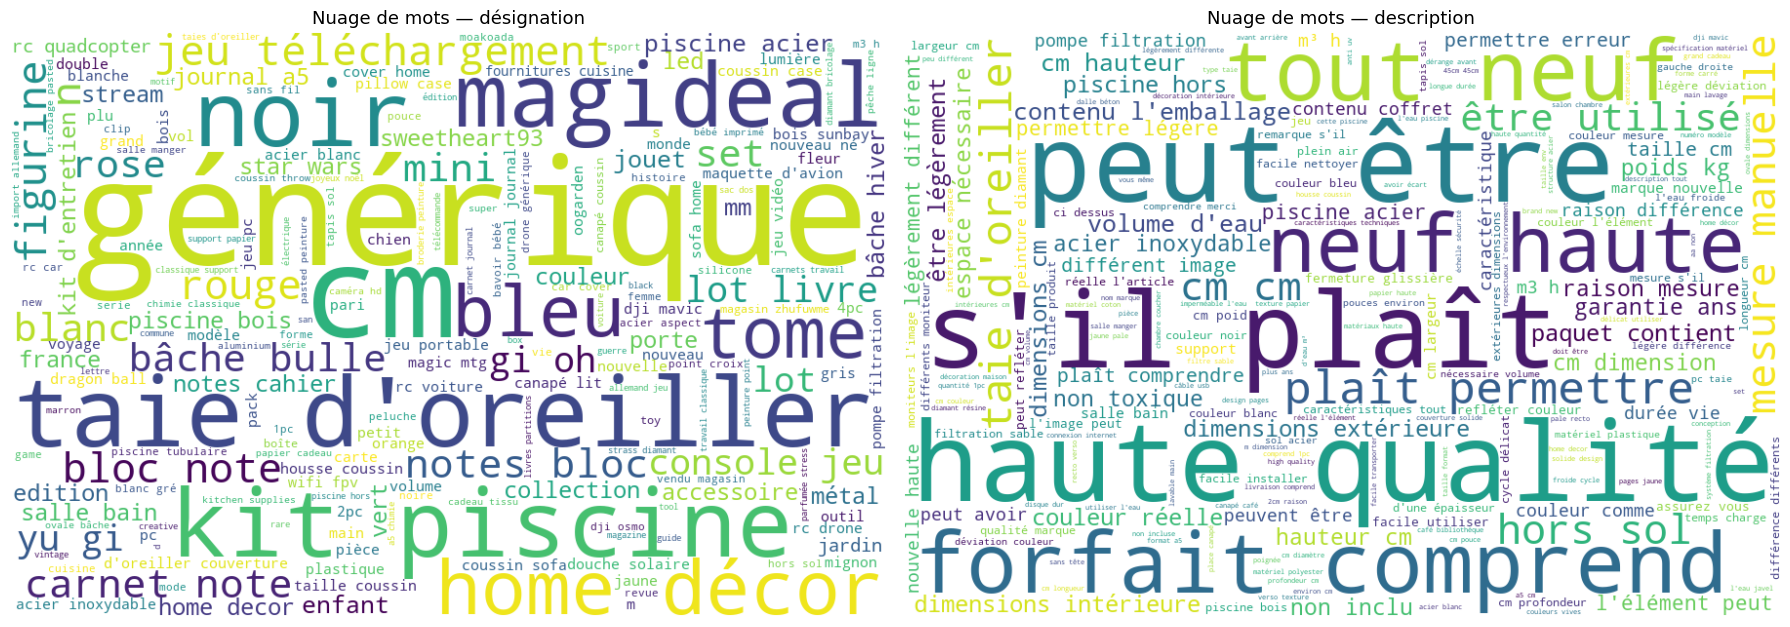

In [82]:
text_desig = ' '.join(data_train['designation_clean'].dropna())
text_desc  = ' '.join(data_train['description_clean'].dropna())

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

wc_desig = WordCloud(width=900, height=600, background_color='white', max_words=200).generate(text_desig)
axes[0].imshow(wc_desig, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Nuage de mots — désignation', fontsize=13)

wc_desc = WordCloud(width=900, height=600, background_color='white', max_words=200).generate(text_desc)
axes[1].imshow(wc_desc, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Nuage de mots — description', fontsize=13)

plt.tight_layout()
save_fig("05_wordclouds.png")
plt.show()


#### Analyse — Nuages de mots & Top mots par classe (Graph 5)

Le vocabulaire des désignations est dominé par des termes génériques de la marketplace (noms de marques, couleurs, tailles). Le vocabulaire des descriptions est plus riche et technique (matériaux, dimensions, caractéristiques).

**Constat métier** : après suppression des stopwords, les mots restants sont majoritairement des **noms de produits, marques ou termes techniques** propres à chaque catégorie. Le nuage de description confirme que certains vendeurs utilisent beaucoup de texte marketing ("qualité", "livraison", "garantie"). Ces termes sont peu discriminants pour la classification et pourraient être ajoutés à la liste de stopwords lors du preprocessing.

**Constat sur le top 3 des classes** : chaque classe possède un vocabulaire caractéristique bien distinct, ce qui est une bonne nouvelle — le signal textuel est fort pour la classification. Les mots les plus fréquents d'une classe sont rarement les plus fréquents d'une autre.

**Validation statistique** : calcul du taux de chevauchement du vocabulaire top-20 entre les 3 premières classes.


In [83]:
top3_classes = data_train['class_name'].value_counts().head(3).index.tolist()
top_vocab = {}
for cls in top3_classes:
    tokens = [w for text in data_train[data_train['class_name'] == cls]['designation_clean']
              for w in text.split() if len(w) > 2]
    top_vocab[cls] = set(w for w, _ in Counter(tokens).most_common(20))

print("=== Chevauchement du vocabulaire Top-20 entre les 3 premières classes ===")
for i, c1 in enumerate(top3_classes):
    for c2 in top3_classes[i+1:]:
        overlap = top_vocab[c1] & top_vocab[c2]
        pct = len(overlap) / 20 * 100
        print(f"  {c1[:20]:20s} ∩ {c2[:20]:20s} : {len(overlap)}/20 mots communs ({pct:.0f}%)")
        if overlap:
            print(f"    Mots communs : {', '.join(sorted(overlap))}")
print()
print("→ Un faible chevauchement confirme que chaque classe a un vocabulaire distinct.")


=== Chevauchement du vocabulaire Top-20 entre les 3 premières classes ===
  Piscines / Spas      ∩ Mobilier             : 2/20 mots communs (10%)
    Mots communs : blanc, bois
  Piscines / Spas      ∩ Modélisme            : 0/20 mots communs (0%)
  Mobilier             ∩ Modélisme            : 1/20 mots communs (5%)
    Mots communs : sac

→ Un faible chevauchement confirme que chaque classe a un vocabulaire distinct.


C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\59651572.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(freq), y=list(mots), ax=ax, palette='Blues_r')
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\59651572.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(freq), y=list(mots), ax=ax, palette='Blues_r')
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\59651572.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(freq), y=list(mots), ax=ax, palette='Blues_r')


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\05b_top_words_per_class.png


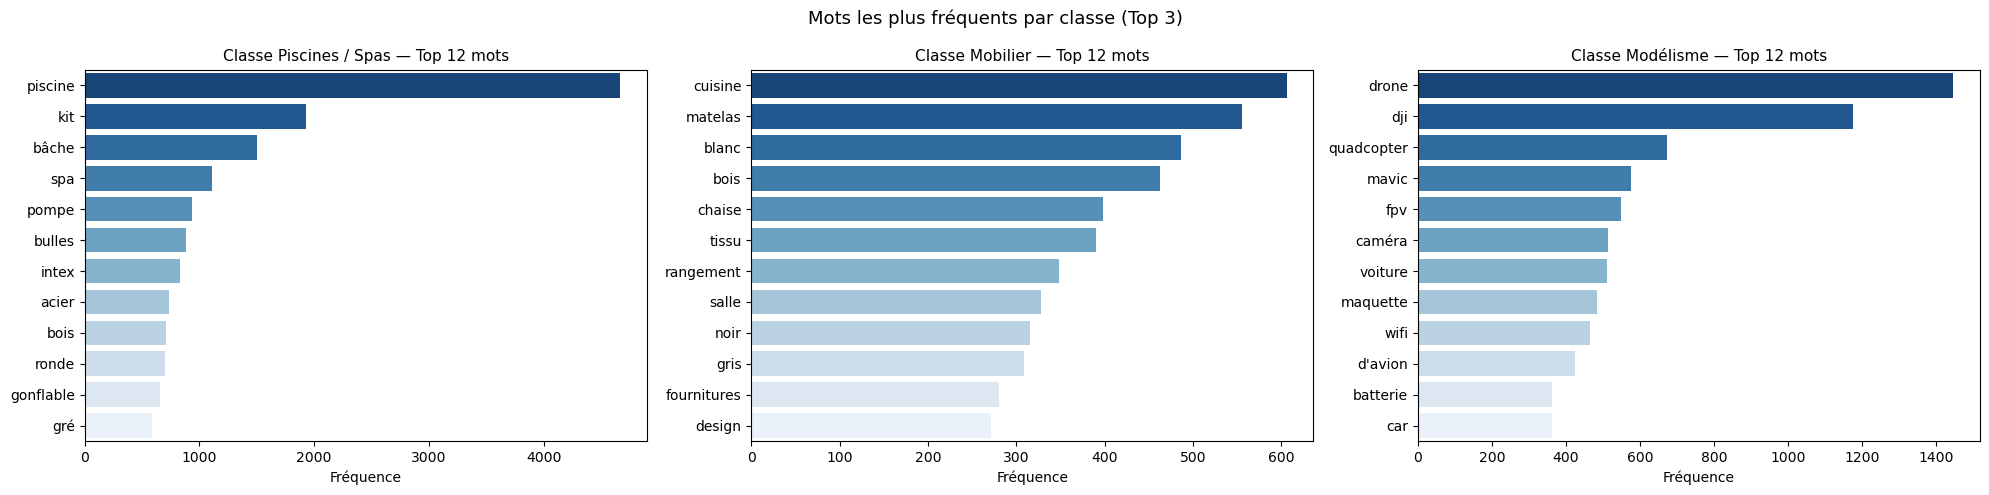

In [84]:
# Mots les plus fréquents pour les 3 premières classes
top3_classes = data_train['class_name'].value_counts().head(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, cls in zip(axes, top3_classes):
    subset = data_train[data_train['class_name'] == cls]['designation_clean']
    tokens = [w for text in subset for w in text.split() if len(w) > 2]
    mc = Counter(tokens).most_common(12)
    if mc:
        mots, freq = zip(*mc)
        sns.barplot(x=list(freq), y=list(mots), ax=ax, palette='Blues_r')
        ax.set_title(f'Classe {cls} — Top 12 mots', fontsize=11)
        ax.set_xlabel('Fréquence')

plt.suptitle('Mots les plus fréquents par classe (Top 3)', fontsize=13)
plt.tight_layout()
save_fig("05b_top_words_per_class.png")
plt.show()


### Statistiques

In [85]:
data_train['len_desig'] = data_train['designation_clean'].str.split().str.len().fillna(0).astype(int)
data_train['len_desc']  = data_train['description_clean'].str.split().str.len().fillna(0).astype(int)

In [86]:
stats = data_train.groupby('class_name').agg(
    nb_produits        = ('designation_clean', 'count'),
    pct_desc_manquante = ('description_clean', lambda x: round(x.isna().mean() * 100, 1)),
    len_desig_moy      = ('len_desig', 'mean'),
    len_desig_med      = ('len_desig', 'median'),
    len_desc_moy       = ('len_desc', lambda x: round(x.dropna().mean(), 1)),
    nb_langues_uniq    = ('language', 'nunique'),
    langue_dominante   = ('language', lambda x: x.value_counts().index[0]),
).round(1)

stats.sort_values('nb_produits', ascending=False)

,nb_produits,pct_desc_manquante,len_desig_moy,len_desig_med,len_desc_moy,nb_langues_uniq,langue_dominante
class_name,,,,,,,
Piscines / Spas,10209,0.0,7.7,7.0,70.0,5,fr
Mobilier,5073,0.0,10.4,10.0,88.3,5,fr
Modélisme,5045,0.0,11.3,12.0,80.0,5,fr
Décoration / Luminaires,4993,0.0,11.0,11.0,101.6,5,fr
Fournitures de bureau,4989,0.0,9.4,9.0,26.6,5,fr
Jouets enfants,4870,0.0,9.8,10.0,64.0,5,fr
Livres / BD,4774,0.0,7.9,6.0,0.6,5,fr
Journaux / Revues,4760,0.0,11.3,9.0,1.5,5,fr
Literie,4303,0.0,10.4,11.0,75.0,5,fr


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\06_heatmap_length_language.png


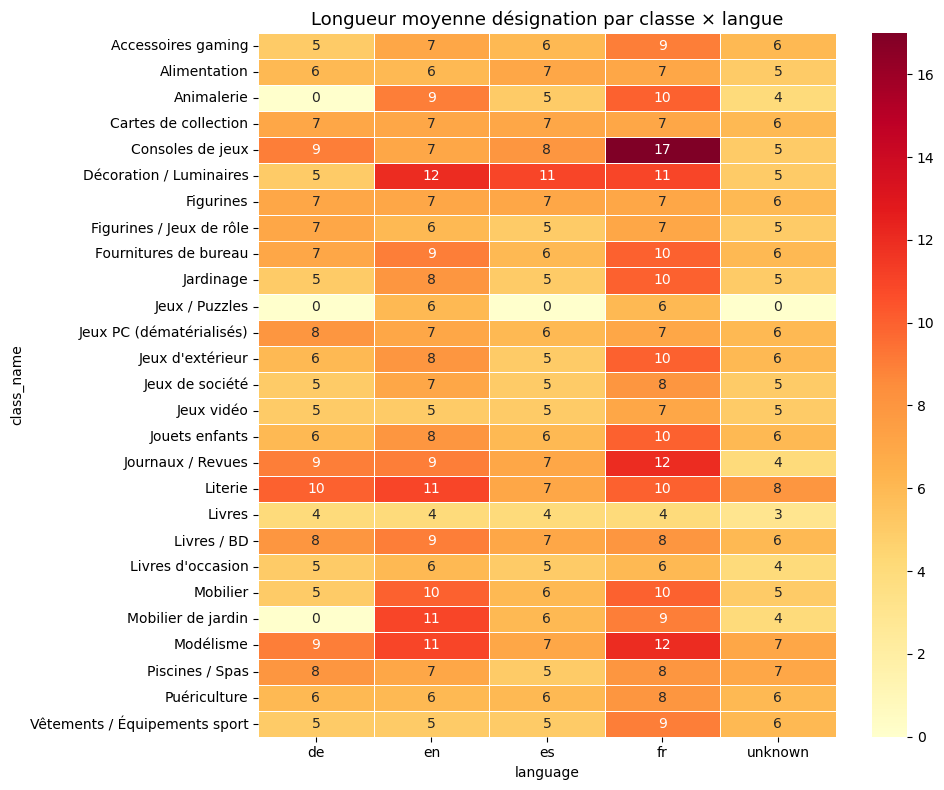

In [87]:
pivot = (data_train.groupby(['class_name', 'language'])['len_desig']
         .mean().unstack(fill_value=0).round(0))

plt.figure(figsize=(10, 8))
sns.heatmap(pivot, cmap='YlOrRd', fmt='.0f', linewidths=0.5, annot=True)
plt.title('Longueur moyenne désignation par classe × langue', fontsize=13)
plt.tight_layout()
save_fig("06_heatmap_length_language.png")
plt.show()


#### Analyse — Heatmap longueur × langue (Graph 6)

La heatmap révèle que la longueur des désignations varie selon **l'interaction classe × langue**. Les produits en allemand ont souvent des désignations plus longues (titres composés), tandis que les produits `unknown` ont des désignations très courtes (textes ambigus ou numériques).

**Constat métier** : la longueur de la désignation est un signal combiné de la classe et de la langue. Par exemple, les *Consoles de jeux* en français ont des désignations très longues (listing détaillé des accessoires inclus), tandis que les *Livres* en toutes langues restent courts (titre seul). Cette interaction peut être exploitée via une feature engineéring : `len_desig × langue encodée`.

**Validation statistique** : vérification que la longueur des désignations diffère bien entre langues pour les classes principales.


In [88]:
# Kruskal-Wallis : longueur désignation diffère-t-elle entre langues ?
lang_groups = [g['len_desig'].values for _, g in data_train.groupby('language') if len(g) > 10]
kw_lang = kruskal(*lang_groups)

print("=== Test Kruskal-Wallis — Longueur désignation par langue ===")
print(f"H = {kw_lang.statistic:.1f}, p = {kw_lang.pvalue:.2e}")
if kw_lang.pvalue < 0.05:
    print("✓ La longueur des désignations diffère significativement entre langues.")
print()
print("Longueur moyenne par langue :")
print(data_train.groupby('language')['len_desig'].agg(['mean', 'median', 'count']).round(1).to_string())


=== Test Kruskal-Wallis — Longueur désignation par langue ===
H = 3248.2, p = 0.00e+00
✓ La longueur des désignations diffère significativement entre langues.

Longueur moyenne par langue :
          mean  median  count
language                     
de         6.4     6.0    812
en         7.9     7.0   9159
es         6.3     6.0   1107
fr         9.1     9.0  71531
unknown    5.6     5.0   2307


### Texte combiné

Texte combiné — min=0  moy=452  max=8765
Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\07_combined_text_length.png


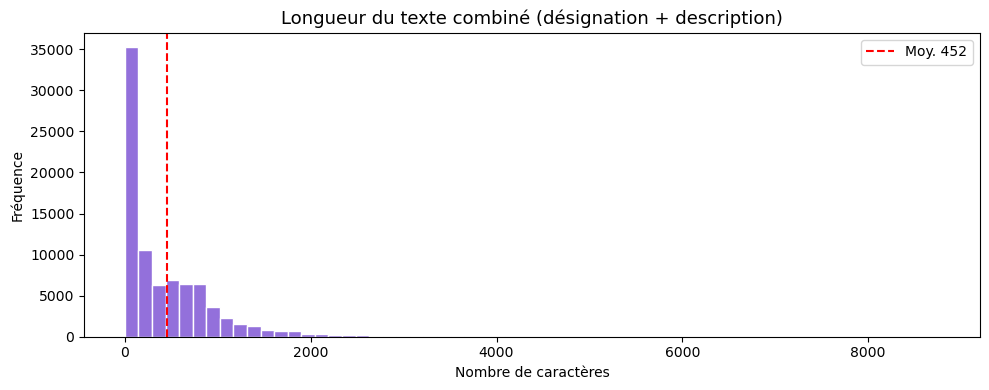

,prdtypecode,text_combined
0,10,olivia personalisiertes notizbuch 150 seiten p...
1,2280,journal arts 133 28/09/2001 l'art marche salon...
2,50,grand stylet ergonomique bleu gamepad nintendo...
3,1280,peluche donald europe disneyland 2000 marionne...
4,2705,guerre tuques luc idées grandeur veut organise...


In [89]:
data_train['text_combined'] = (data_train['designation_clean'].fillna('') + ' ' +
                                data_train['description_clean']).str.strip()
data_train['len_combined'] = data_train['text_combined'].str.len()

print(f'Texte combiné — '
      f'min={data_train["len_combined"].min()}  '
      f'moy={data_train["len_combined"].mean():.0f}  '
      f'max={data_train["len_combined"].max()}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(data_train['len_combined'], bins=60, color='mediumpurple', edgecolor='white')
ax.axvline(data_train['len_combined'].mean(), color='red', linestyle='--',
           label=f'Moy. {data_train["len_combined"].mean():.0f}')
ax.set_title('Longueur du texte combiné (désignation + description)', fontsize=13)
ax.set_xlabel('Nombre de caractères')
ax.set_ylabel('Fréquence')
ax.legend()
plt.tight_layout()
save_fig("07_combined_text_length.png")
plt.show()

data_train[['prdtypecode', 'text_combined']].head(5)


---
## Avant / Après Preprocessing — Visualisation (Graphs A–C)

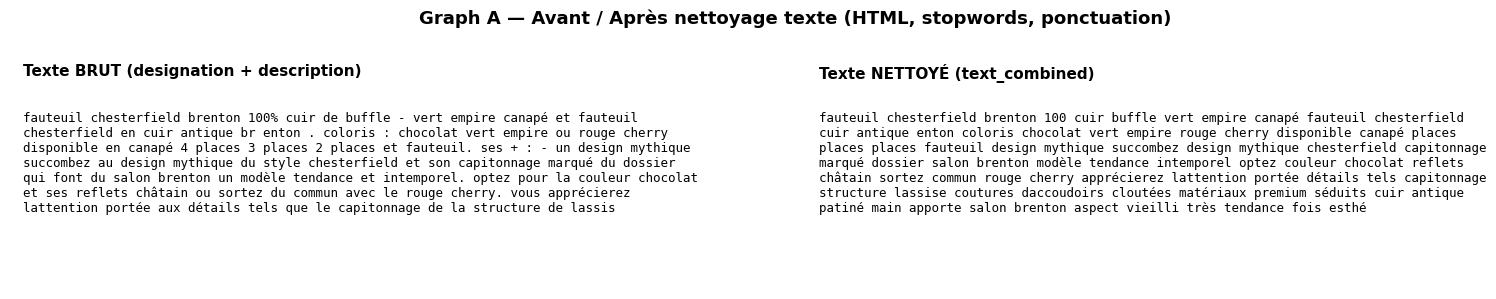

Sauvegardé : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graphA_avant_apres_texte.png


In [90]:
# ─── Graph A : Exemple texte brut vs nettoyé ──────────────────────────────
import textwrap

sample_idx = data_train[data_train['has_desc'] == 1].index[5]
raw  = data_train.loc[sample_idx, 'designation'] + ' ' + str(data_train.loc[sample_idx, 'description'])
clean = data_train.loc[sample_idx, 'text_combined']

fig, axes = plt.subplots(1, 2, figsize=(16, 3))
for ax, txt, title, color in zip(
    axes,
    [raw[:600], clean[:600]],
    ['Texte BRUT (designation + description)', 'Texte NETTOYÉ (text_combined)'],
    ['#ffcccc', '#ccffcc']
):
    ax.set_facecolor(color)
    ax.text(0.02, 0.95, title, transform=ax.transAxes, fontsize=11, fontweight='bold', va='top')
    wrapped = textwrap.fill(txt, width=90)
    ax.text(0.02, 0.75, wrapped, transform=ax.transAxes, fontsize=9, va='top', wrap=True,
            fontfamily='monospace')
    ax.axis('off')

plt.suptitle("Graph A — Avant / Après nettoyage texte (HTML, stopwords, ponctuation)", fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'graphA_avant_apres_texte.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Sauvegardé : {fig_path}")

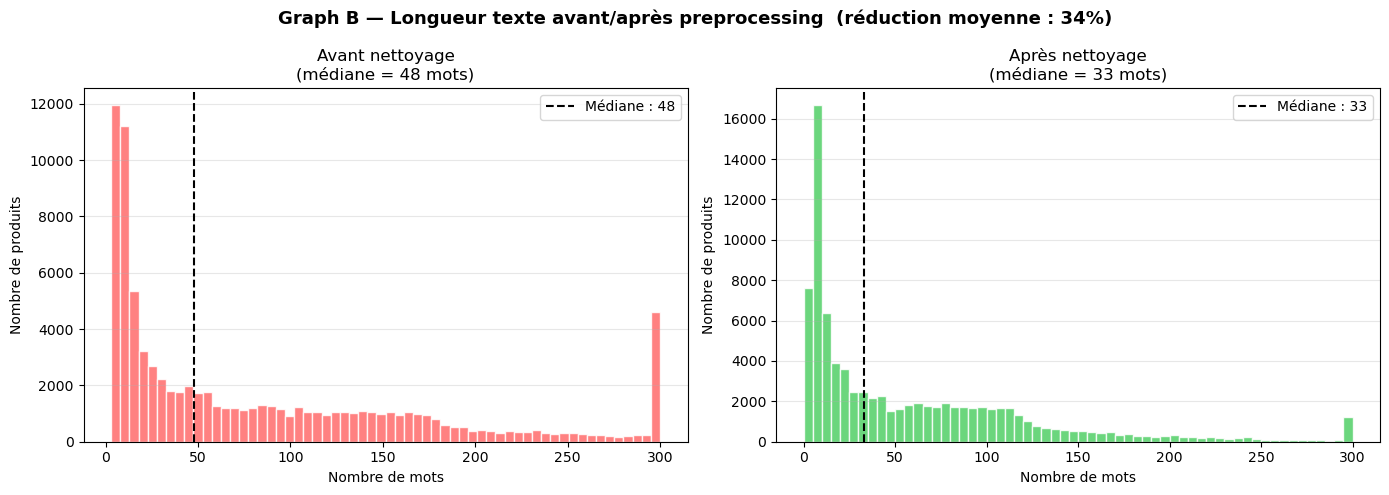

Sauvegardé : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graphB_longueur_avant_apres.png


In [91]:
# ─── Graph B : Distribution longueur texte avant / après nettoyage ──────────
len_raw   = (data_train['designation'].fillna('') + ' ' + data_train['description'].fillna('')).str.split().str.len()
len_clean = data_train['text_combined'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, lengths, title, color, label in zip(
    axes,
    [len_raw, len_clean],
    ['Avant nettoyage', 'Après nettoyage'],
    ['#ff6b6b', '#51cf66'],
    ['Texte brut', 'text_combined']
):
    ax.hist(lengths.clip(upper=300), bins=60, color=color, alpha=0.85, edgecolor='white')
    ax.axvline(lengths.median(), color='black', linestyle='--', linewidth=1.5, label=f'Médiane : {lengths.median():.0f}')
    ax.set_title(f'{title}\n(médiane = {lengths.median():.0f} mots)', fontsize=12)
    ax.set_xlabel('Nombre de mots')
    ax.set_ylabel('Nombre de produits')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

reduction = (1 - len_clean.mean() / len_raw.mean()) * 100
plt.suptitle(f"Graph B — Longueur texte avant/après preprocessing  (réduction moyenne : {reduction:.0f}%)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'graphB_longueur_avant_apres.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Sauvegardé : {fig_path}")

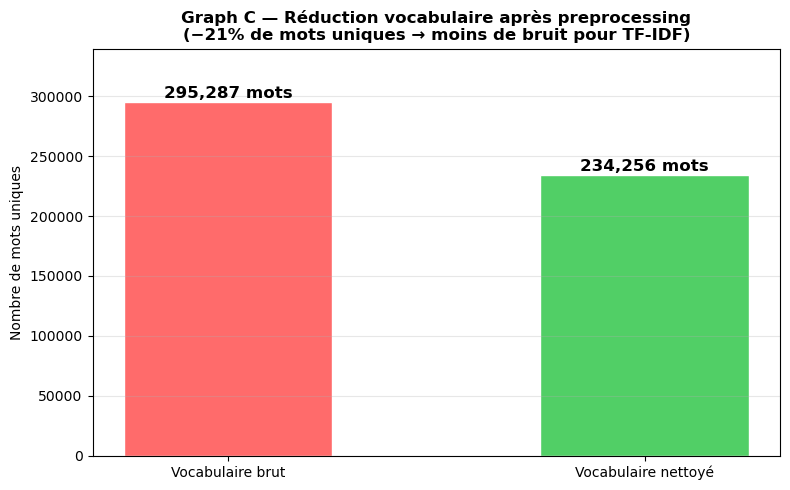

Sauvegardé : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graphC_vocabulaire_avant_apres.png

Vocabulaire brut   : 295,287 mots uniques
Vocabulaire nettoyé: 234,256 mots uniques
Réduction          : -21%


In [92]:
# ─── Graph C : Taille vocabulaire avant / après nettoyage ─────────────────
vocab_raw   = set(w for txt in (data_train['designation'].fillna('') + ' ' + data_train['description'].fillna('')).str.lower()
                  for w in str(txt).split())
vocab_clean = set(w for txt in data_train['text_combined'].dropna() for w in str(txt).split())

labels  = ['Vocabulaire brut', 'Vocabulaire nettoyé']
sizes   = [len(vocab_raw), len(vocab_clean)]
colors  = ['#ff6b6b', '#51cf66']
reduction_pct = (1 - sizes[1] / sizes[0]) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, sizes, color=colors, edgecolor='white', width=0.5)
for bar, size in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
            f'{size:,} mots', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Nombre de mots uniques')
ax.set_title(f'Graph C — Réduction vocabulaire après preprocessing\n'
             f'(−{reduction_pct:.0f}% de mots uniques → moins de bruit pour TF-IDF)',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(sizes) * 1.15)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'graphC_vocabulaire_avant_apres.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Sauvegardé : {fig_path}")
print(f"\nVocabulaire brut   : {sizes[0]:,} mots uniques")
print(f"Vocabulaire nettoyé: {sizes[1]:,} mots uniques")
print(f"Réduction          : -{reduction_pct:.0f}%")

---
## Auto-recadrage des images dézoomées

Certaines images Rakuten ont le produit centré dans un grand espace vide (fond blanc). L'algorithme détecte automatiquement la zone de contenu non-blanc et recadre l'image.


In [93]:
print(f'Images manquantes (join) : {data_train["image_name"].isna().sum()}')
imgs_par_classe = data_train.groupby('prdtypecode')['image_name'].count()
print(f'Images par classe — min: {imgs_par_classe.min()}  '
      f'max: {imgs_par_classe.max()}  '
      f'moy: {imgs_par_classe.mean():.0f}')

Images manquantes (join) : 0
Images par classe — min: 764  max: 10209  moy: 3145


In [94]:
from PIL import Image

IMAGES_PATH = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train"

sample = (data_train.groupby('prdtypecode')
          .first().reset_index()[['prdtypecode', 'class_name', 'image_name']].dropna())

# Test sur la première image
row = sample.iloc[0]
img_path = os.path.join(IMAGES_PATH, row['image_name'])
print(f'Chemin testé : {repr(img_path)}')
print(f'Existe       : {os.path.exists(img_path)}')
try:
    img = Image.open(img_path)
    print(f'Image OK     : {img.size} {img.mode}')
except Exception as e:
    print(f'ERREUR       : {type(e).__name__}: {e}')

Chemin testé : 'C:\\Users\\veyss\\Nouveau dossier\\nov25_alt1_mle_rakuten\\data\\raw\\images\\image_train\\image_1263597046_product_3804725264.jpg'
Existe       : True
Image OK     : (500, 500) RGB


In [95]:
def load_img(image_name):
    path = os.path.join(IMAGES_PATH, image_name)
    return Image.open(path).convert('RGB')

In [96]:
def auto_crop(img, bg_threshold=240, margin_pct=0.02):
    """
    Détecte la zone de contenu (pixels non-blancs) et recadre l'image.
    
    Paramètres
    ----------
    img           : PIL.Image
    bg_threshold  : seuil luminosité (0-255) — pixels >= seuil = fond
    margin_pct    : marge à ajouter autour du contenu (fraction de la taille)
    
    Retourne
    --------
    cropped  : PIL.Image recadrée
    zoom_ratio : float — rapport surface totale / surface recadrée (>1 = zoom effectif)
    bbox     : tuple (left, top, right, bottom) en pixels originaux
    """
    rgb   = img.convert('RGB')
    arr   = np.array(rgb)                          # (H, W, 3)
    
    # Masque : pixel est "contenu" si l'une des 3 composantes < seuil
    # (gère aussi les fonds légèrement grisés ou colorés)
    mask = np.any(arr < bg_threshold, axis=2)      # (H, W) bool
    
    if not mask.any():
        # Image entièrement blanche → pas de recadrage
        return img, 1.0, (0, 0, img.width, img.height)
    
    H, W = mask.shape
    rows = np.where(mask.any(axis=1))[0]           # lignes ayant du contenu
    cols = np.where(mask.any(axis=0))[0]           # colonnes ayant du contenu
    
    rmin, rmax = rows[0], rows[-1]
    cmin, cmax = cols[0], cols[-1]
    
    # Marge proportionnelle à la taille de l'image
    margin_h = int(H * margin_pct)
    margin_w = int(W * margin_pct)
    rmin = max(0,     rmin - margin_h)
    rmax = min(H - 1, rmax + margin_h)
    cmin = max(0,     cmin - margin_w)
    cmax = min(W - 1, cmax + margin_w)
    
    bbox       = (cmin, rmin, cmax + 1, rmax + 1)  # format PIL (left, top, right, bottom)
    crop_area  = (rmax - rmin + 1) * (cmax - cmin + 1)
    zoom_ratio = (H * W) / crop_area
    
    return img.crop(bbox), zoom_ratio, bbox


def load_img(image_name):
    path = os.path.join(IMAGES_PATH, image_name)
    return Image.open(path).convert('RGB')

print("Fonction auto_crop() définie.")


Fonction auto_crop() définie.


In [97]:
from tqdm import tqdm

# Scan complet : toutes les images du dataset via image_name + class_name
# ⚠️ ~84 916 images — environ 10-15 min sur CPU

DEZOOM_SEUIL = 1/0.7  # produit < 70% de la surface → "mal cadré"

full_records = []
for _, row in tqdm(data_train[['image_name', 'class_name', 'prdtypecode']].iterrows(),
                   total=len(data_train), desc="Scan images"):
    try:
        img = load_img(row['image_name'])
        _, zoom_ratio, _ = auto_crop(img, bg_threshold=240)
        full_records.append({
            'image_name':  row['image_name'],
            'class_name':  row['class_name'],
            'prdtypecode': row['prdtypecode'],
            'zoom_ratio':  zoom_ratio,
            'mal_cadre':   int(zoom_ratio > DEZOOM_SEUIL),
        })
    except Exception:
        full_records.append({
            'image_name':  row['image_name'],
            'class_name':  row['class_name'],
            'prdtypecode': row['prdtypecode'],
            'zoom_ratio':  None,
            'mal_cadre':   None,
        })

full_scan_df = pd.DataFrame(full_records)
print(f"\nScan terminé : {len(full_scan_df):,} images")
print(f"  Erreurs de chargement : {full_scan_df['zoom_ratio'].isna().sum()}")
full_scan_df.head(5)

Scan images: 100%|██████████| 84916/84916 [07:01<00:00, 201.50it/s]


Scan terminé : 84,916 images
  Erreurs de chargement : 0


,image_name,class_name,prdtypecode,zoom_ratio,mal_cadre
0,image_1263597046_product_3804725264.jpg,Livres d'occasion,10,6.685922,1
1,image_1008141237_product_436067568.jpg,Journaux / Revues,2280,4.388737,1
2,image_938777978_product_201115110.jpg,Accessoires gaming,50,1.750664,1
3,image_457047496_product_50418756.jpg,Jouets enfants,1280,1.725423,1
4,image_1077757786_product_278535884.jpg,Livres,2705,3.639646,1


In [98]:
data_train = data_train.merge(
    full_scan_df[['image_name', 'zoom_ratio']],
    on='image_name',
    how='left'
)

In [99]:
# Sauvegarde des images recadrées dans data/processed/image_crop
# Utilise full_scan_df (déjà calculé) pour savoir quelles images recadrer
# → évite de recalculer auto_crop une 2ème fois

CROP_OUTPUT_DIR = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\image_crop"
os.makedirs(CROP_OUTPUT_DIR, exist_ok=True)

OUTPUT_SIZE = (500, 500)

n_cropped = 0
n_copied  = 0
n_errors  = 0

for _, row in tqdm(full_scan_df.iterrows(), total=len(full_scan_df), desc="Sauvegarde image_crop"):
    src_path = os.path.join(IMAGES_PATH, row['image_name'])
    dst_path = os.path.join(CROP_OUTPUT_DIR, row['image_name'])

    if os.path.exists(dst_path):   # déjà traité → on skip
        continue

    try:
        img = Image.open(src_path).convert('RGB')

        if row['mal_cadre'] == 1:
            # zoom_ratio déjà connu → recadrage direct sans recalcul
            cropped, _, _ = auto_crop(img, bg_threshold=240)
            out = cropped.resize(OUTPUT_SIZE, Image.LANCZOS)
            n_cropped += 1
        else:
            # bien cadrée → original conservé
            out = img
            n_copied += 1

        out.save(dst_path, format='JPEG', quality=95)

    except Exception:
        n_errors += 1

print(f"\nTerminé :")
print(f"  Images recadrées (zoom appliqué) : {n_cropped:,}")
print(f"  Images conservées (bien cadrées) : {n_copied:,}")
print(f"  Erreurs                          : {n_errors}")
print(f"  Total sauvegardé                 : {n_cropped + n_copied:,}")
print(f"\nDossier : {CROP_OUTPUT_DIR}")

Sauvegarde image_crop: 100%|██████████| 84916/84916 [00:03<00:00, 26418.53it/s]


Terminé :
  Images recadrées (zoom appliqué) : 0
  Images conservées (bien cadrées) : 0
  Erreurs                          : 0
  Total sauvegardé                 : 0

Dossier : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\image_crop


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\09_cadrage_complet_par_classe.png


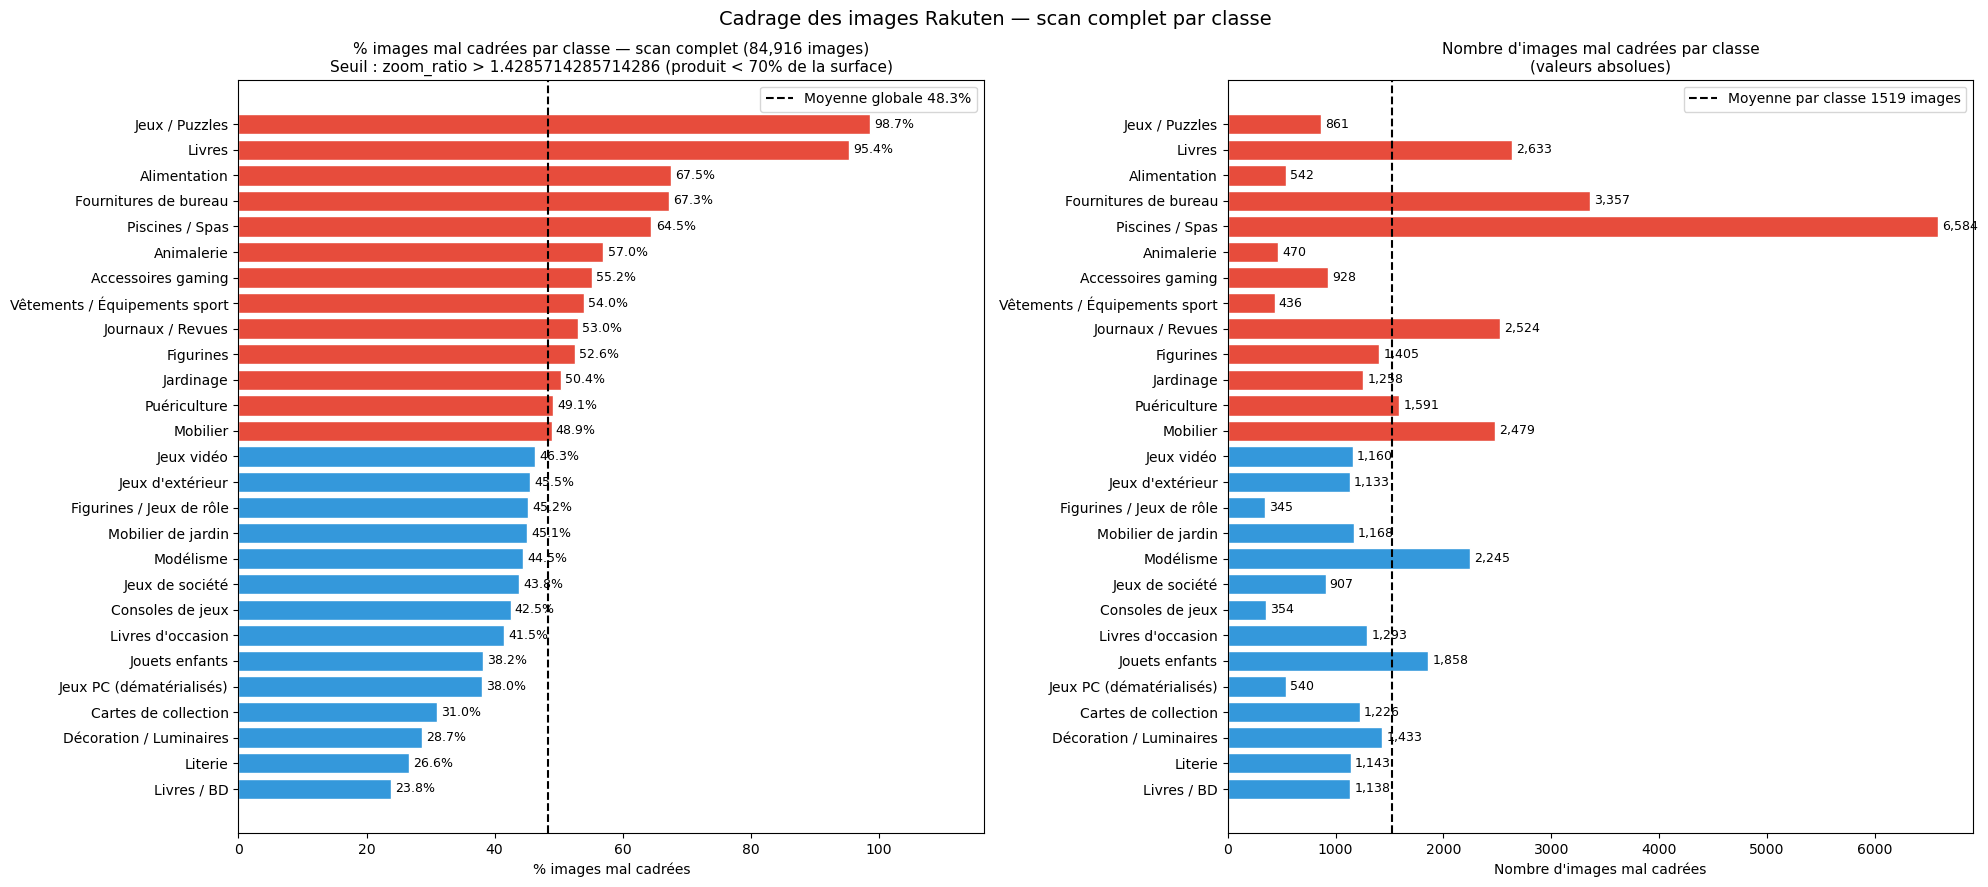

=== Nombre d'images mal cadrées par classe (seuil zoom_ratio > 1.4285714285714286) ===

Classe                                 Total   Mal cadrées        %   Zoom moy
────────────────────────────────────────────────────────────────────────────────
  Jeux / Puzzles                       872.0         861.0    98.7%      2.91x ◄
  Livres                             2,761.0       2,633.0    95.4%      2.85x ◄
  Alimentation                         803.0         542.0    67.5%      2.71x
  Fournitures de bureau              4,989.0       3,357.0    67.3%      2.91x
  Piscines / Spas                    10,209.0       6,584.0    64.5%      2.80x
  Animalerie                           824.0         470.0    57.0%      1.91x
  Accessoires gaming                 1,681.0         928.0    55.2%      2.25x
  Vêtements / Équipements sport        807.0         436.0    54.0%      3.42x
  Journaux / Revues                  4,760.0       2,524.0    53.0%      1.98x
  Figurines                         

In [100]:
valid = full_scan_df.dropna(subset=['mal_cadre'])
global_pct_full = valid['mal_cadre'].mean() * 100

counts = (valid.groupby('class_name')
          .agg(
              total        = ('image_name',  'count'),
              mal_cadre    = ('mal_cadre',   'sum'),
              pct_mal      = ('mal_cadre',   lambda x: round(x.mean() * 100, 1)),
              zoom_moyen   = ('zoom_ratio',  lambda x: round(x.mean(), 2)),
          )
          .sort_values('pct_mal', ascending=False)
          .astype({'mal_cadre': int, 'total': int}))

# --- Graphique ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))

colors = ['#e74c3c' if p > global_pct_full else '#3498db' for p in counts['pct_mal']]
bars = ax1.barh(counts.index, counts['pct_mal'], color=colors, edgecolor='white')
ax1.axvline(global_pct_full, color='black', linestyle='--', linewidth=1.5,
            label=f'Moyenne globale {global_pct_full:.1f}%')
ax1.bar_label(bars, labels=[f"{v:.1f}%" for v in counts['pct_mal']], padding=3, fontsize=9)
ax1.set_title(f'% images mal cadrées par classe — scan complet ({len(valid):,} images)\n'
              f'Seuil : zoom_ratio > {DEZOOM_SEUIL} (produit < 70% de la surface)', fontsize=11)
ax1.set_xlabel('% images mal cadrées')
ax1.invert_yaxis()
ax1.legend()
ax1.set_xlim(0, counts['pct_mal'].max() * 1.18)

bars2 = ax2.barh(counts.index, counts['mal_cadre'], color=colors, edgecolor='white')
ax2.axvline(valid['mal_cadre'].sum() / len(counts), color='black', linestyle='--', linewidth=1.5,
            label=f'Moyenne par classe {valid["mal_cadre"].sum()/len(counts):.0f} images')
ax2.bar_label(bars2, labels=[f"{v:,}" for v in counts['mal_cadre']], padding=3, fontsize=9)
ax2.set_title('Nombre d\'images mal cadrées par classe\n(valeurs absolues)', fontsize=11)
ax2.set_xlabel('Nombre d\'images mal cadrées')
ax2.invert_yaxis()
ax2.legend()

plt.suptitle('Cadrage des images Rakuten — scan complet par classe', fontsize=14)
plt.tight_layout()
save_fig("09_cadrage_complet_par_classe.png")
plt.show()

# Tableau complet
print(f"=== Nombre d'images mal cadrées par classe (seuil zoom_ratio > {DEZOOM_SEUIL}) ===\n")
print(f"{'Classe':35s}  {'Total':>7}  {'Mal cadrées':>12}  {'%':>7}  {'Zoom moy':>9}")
print("─" * 80)
for cls, r in counts.iterrows():
    flag = " ◄" if r['pct_mal'] > global_pct_full * 1.5 else ""
    print(f"  {cls:33s}  {r['total']:>7,}  {r['mal_cadre']:>12,}  {r['pct_mal']:>6.1f}%  {r['zoom_moyen']:>8.2f}x{flag}")
print("─" * 80)
print(f"  {'TOTAL':33s}  {valid['image_name'].count():>7,}  {int(valid['mal_cadre'].sum()):>12,}  {global_pct_full:>6.1f}%")


In [101]:
from scipy.stats import chi2_contingency

full_scan_df['mal_cadre'] = (full_scan_df['zoom_ratio'] > 1/0.7).astype(int)

# Supprimer les lignes avec NaN dans zoom_ratio ou class_name
df_valid = full_scan_df.dropna(subset=['zoom_ratio', 'mal_cadre', 'class_name'])
print(f"Lignes valides : {len(df_valid)} / {len(full_scan_df)}")
print(f"% mal cadrées : {df_valid['mal_cadre'].mean()*100:.1f}%")
print(df_valid['mal_cadre'].value_counts())
print()

contingency = pd.crosstab(df_valid['class_name'], df_valid['mal_cadre'])
print(f"Shape contingency : {contingency.shape}")
chi2, p, dof, _ = chi2_contingency(contingency)
print(f"Chi² = {chi2:.2f}, p = {p:.2e}, ddl = {dof}")

Lignes valides : 84916 / 84916
% mal cadrées : 48.3%
mal_cadre
0    43905
1    41011
Name: count, dtype: int64

Shape contingency : (27, 2)
Chi² = 8985.31, p = 0.00e+00, ddl = 26


In [102]:
# Scan d'un échantillon pour trouver les images les plus "dézoomées"
# (= celles où le produit n'occupe qu'une petite fraction des 500x500)

SCAN_N = 2000  # nombre d'images à analyser (augmenter pour un scan plus exhaustif)
sample_names = data_train['image_name'].dropna().sample(SCAN_N, random_state=42).tolist()

results = []
for name in sample_names:
    try:
        img = load_img(name)
        _, zoom_ratio, bbox = auto_crop(img, bg_threshold=240)
        content_pct = 100 / zoom_ratio           # % de l'image occupé par le produit
        results.append({
            'image_name': name,
            'zoom_ratio': round(zoom_ratio, 2),
            'content_pct': round(content_pct, 1),
            'bbox': bbox,
        })
    except Exception:
        pass

scan_df = pd.DataFrame(results).sort_values('zoom_ratio', ascending=False)

print(f"Images scannées : {len(scan_df)}")
print(f"\nDistribution du zoom_ratio (surface totale / surface produit) :")
print(scan_df['zoom_ratio'].describe().round(2))
print(f"\nImages avec produit < 25% de la surface ({SCAN_N} images scannées) :")
print(f"  {(scan_df['content_pct'] < 25).sum()} images ({(scan_df['content_pct'] < 25).mean()*100:.1f}%)")
print(f"\nTop 10 images les plus dézoomées :")
print(scan_df.head(10)[['image_name', 'zoom_ratio', 'content_pct', 'bbox']].to_string(index=False))


Images scannées : 2000

Distribution du zoom_ratio (surface totale / surface produit) :
count    2000.00
mean        2.15
std         2.31
min         1.00
25%         1.22
50%         1.42
75%         2.00
max        30.32
Name: zoom_ratio, dtype: float64

Images avec produit < 25% de la surface (2000 images scannées) :
  175 images (8.8%)

Top 10 images les plus dézoomées :
                             image_name  zoom_ratio  content_pct                 bbox
   image_316914600_product_46660147.jpg       30.32          3.3 (207, 201, 292, 298)
image_1096605441_product_1657058325.jpg       28.31          3.5 (182, 218, 320, 282)
image_1064957014_product_1144274013.jpg       25.64          3.9 (196, 194, 288, 300)
image_1309102771_product_4179633560.jpg       25.56          3.9 (214, 183, 287, 317)
   image_689916942_product_57643271.jpg       22.32          4.5 (198, 198, 298, 310)
image_1309122194_product_4179727301.jpg       21.16          4.7 (181, 206, 320, 291)
image_1241423141_pr

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\08_auto_crop_avant_apres.png


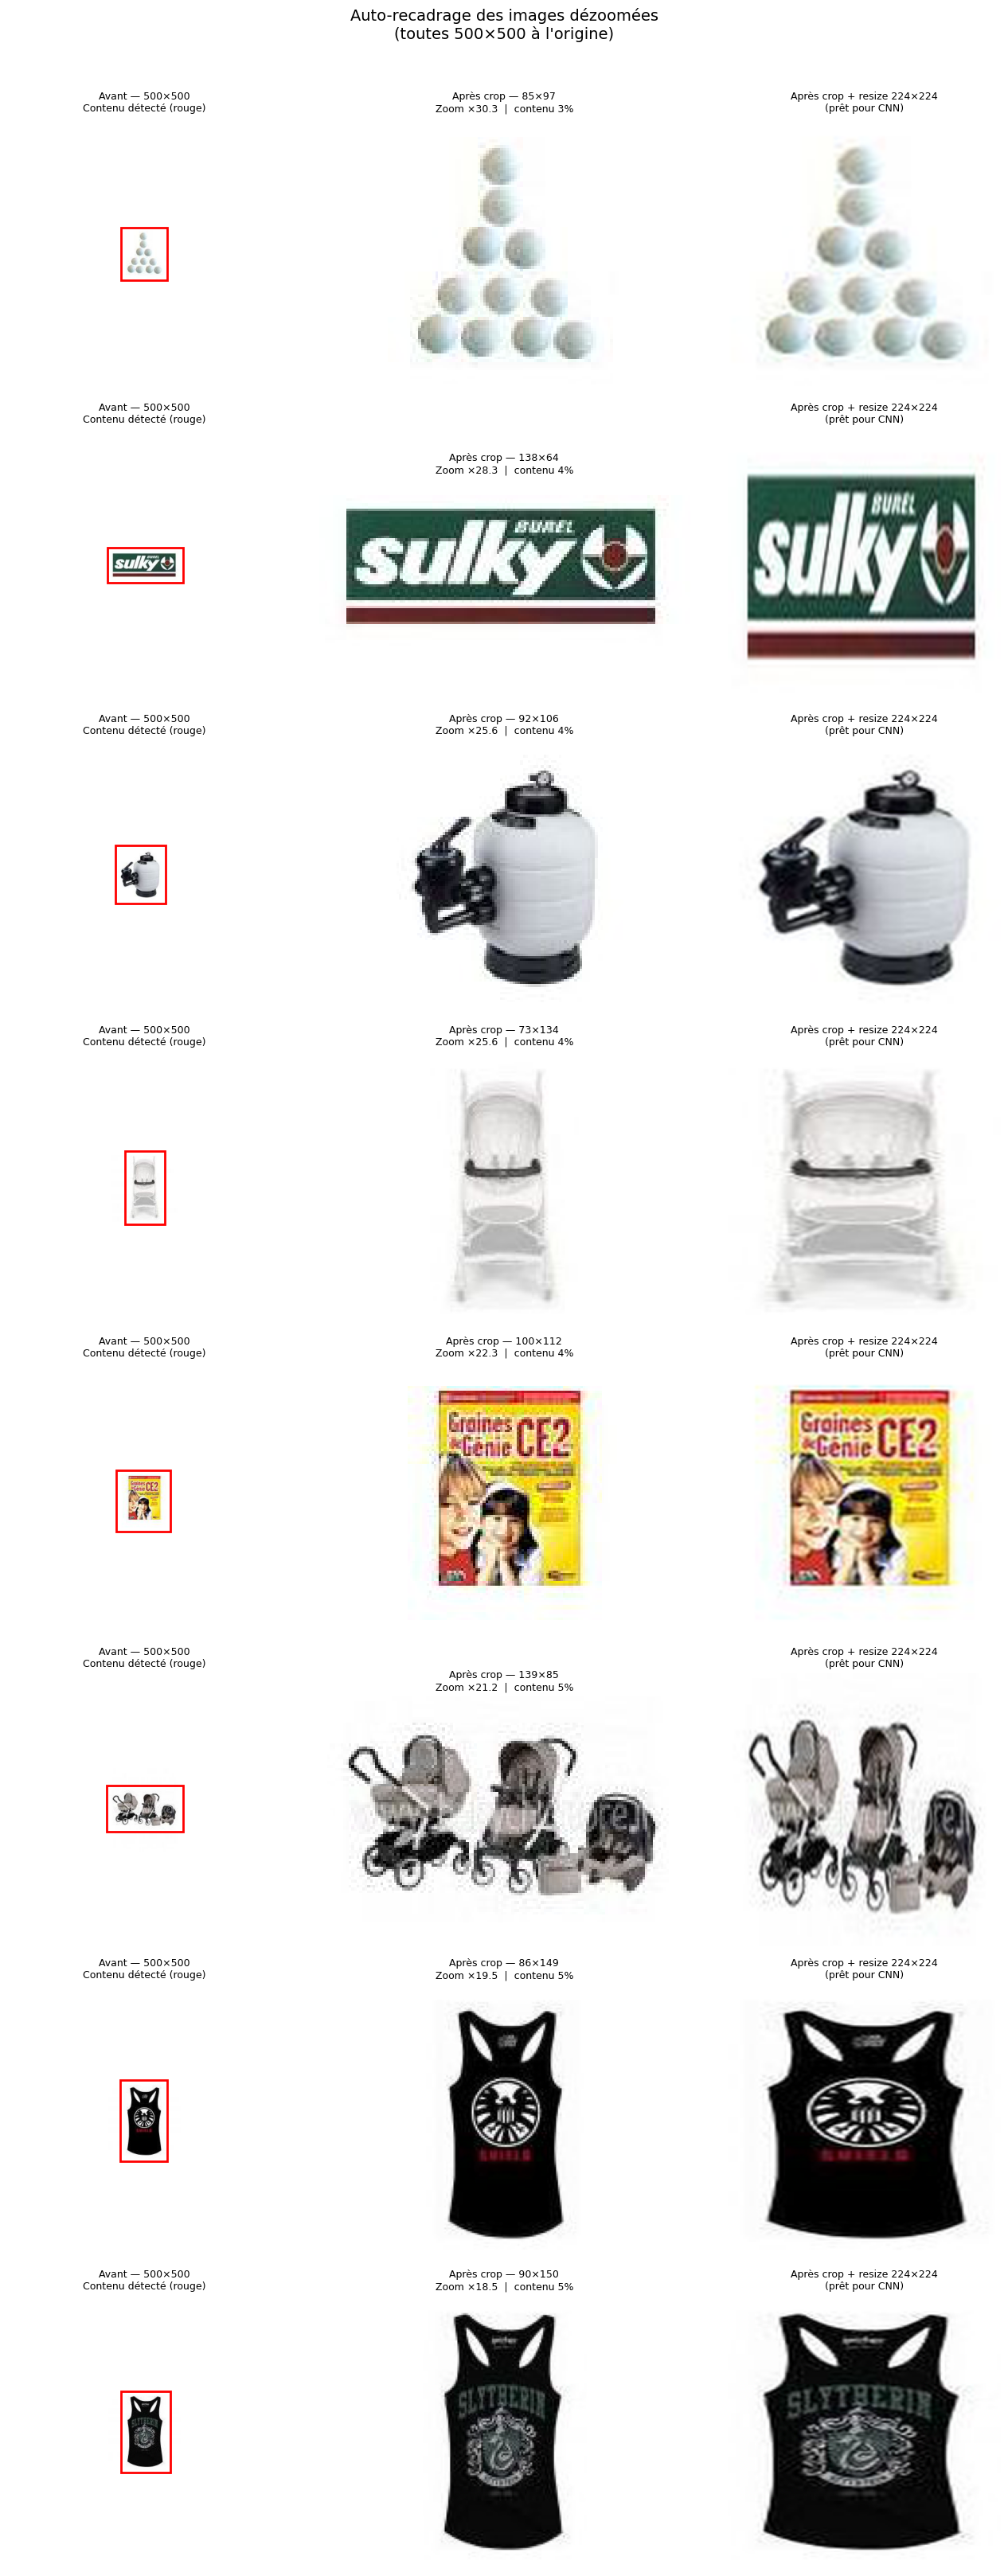

In [103]:
# Avant / Après — affichage des 8 images les plus dézoomées
N_SHOW = 8
top_dezoom = scan_df.head(N_SHOW)

fig, axes = plt.subplots(N_SHOW, 3, figsize=(14, N_SHOW * 4))
fig.suptitle("Auto-recadrage des images dézoomées\n(toutes 500×500 à l'origine)", fontsize=14, y=1.01)

for i, (_, row) in enumerate(top_dezoom.iterrows()):
    img     = load_img(row['image_name'])
    cropped, zoom_ratio, bbox = auto_crop(img, bg_threshold=240)

    # Colonne 1 : image originale avec rectangle de détection
    import matplotlib.patches as patches
    axes[i, 0].imshow(img)
    left, top, right, bottom = bbox
    rect = patches.Rectangle(
        (left, top), right - left, bottom - top,
        linewidth=2, edgecolor='red', facecolor='none'
    )
    axes[i, 0].add_patch(rect)
    axes[i, 0].set_title(f"Avant — {img.size[0]}×{img.size[1]}\nContenu détecté (rouge)", fontsize=9)
    axes[i, 0].axis('off')

    # Colonne 2 : image recadrée
    axes[i, 1].imshow(cropped)
    cw, ch = cropped.size
    axes[i, 1].set_title(f"Après crop — {cw}×{ch}\nZoom ×{zoom_ratio:.1f}  |  contenu {100/zoom_ratio:.0f}%", fontsize=9)
    axes[i, 1].axis('off')

    # Colonne 3 : image recadrée + resize 224×224 (format final pour modèle)
    resized = cropped.resize((224, 224), Image.LANCZOS)
    axes[i, 2].imshow(resized)
    axes[i, 2].set_title("Après crop + resize 224×224\n(prêt pour CNN)", fontsize=9)
    axes[i, 2].axis('off')

plt.tight_layout()
save_fig("08_auto_crop_avant_apres.png")
plt.show()


## Test mbert pour vectorisation

https://huggingface.co/google-bert/bert-base-multilingual-cased

In [104]:
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')
model = BertModel.from_pretrained("bert-base-multilingual-cased")

In [105]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(119547, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=Fals

---
## Preprocessing — Préparation pour la modélisation

### Texte brut pour Transformers (text_combined_raw)

On conserve une version **sans suppression de stopwords** pour les modèles BERT/SentenceTransformer qui ont besoin du contexte syntaxique complet.


In [106]:
# text_combined_raw : designation + description bruts (juste nettoyage HTML déjà fait)
# → à utiliser avec les tokenizers Transformers (mBERT, CamemBERT, SentenceTransformer)
data_train['text_combined_raw'] = (
    data_train['designation'].fillna('') + ' ' +
    data_train['description'].fillna('')
).str.strip()

print(f"text_combined_raw — {len(data_train):,} lignes")
print(f"Exemple (index 2) : {data_train['text_combined_raw'].iloc[2][:120]}")
print(f"text_combined — {len(data_train):,} lignes")
print(f"Exemple (index 2) : {data_train['text_combined'].iloc[2][:120]}")
print()
print("Rappel des deux versions texte disponibles :")
print("  text_combined     → tokenisé NLTK, stopwords supprimés  → TF-IDF / ML classique")
print("  text_combined_raw → texte brut après nettoyage HTML      → Transformers / BERT")


text_combined_raw — 84,916 lignes
Exemple (index 2) : grand stylet ergonomique bleu gamepad nintendo wii u - speedlink pilot style pilot style touch pen de marque speedlink e
text_combined — 84,916 lignes
Exemple (index 2) : grand stylet ergonomique bleu gamepad nintendo wii speedlink pilot pilot touch pen marque speedlink stylet ergonomique g

Rappel des deux versions texte disponibles :
  text_combined     → tokenisé NLTK, stopwords supprimés  → TF-IDF / ML classique
  text_combined_raw → texte brut après nettoyage HTML      → Transformers / BERT


### Encodage de la cible (LabelEncoder)

Les codes `prdtypecode` sont non-consécutifs (10, 40, 50… 2905). Les modèles sklearn et PyTorch attendent des entiers consécutifs de 0 à N-1.


In [107]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data_train['label'] = le.fit_transform(data_train['prdtypecode'])

label_mapping = dict(zip(le.classes_.tolist(), le.transform(le.classes_).tolist()))
print("Mapping prdtypecode → label (0..26) :")
for code, lbl in sorted(label_mapping.items()):
    cls = CLASS_NAMES.get(code, '?')
    print(f"  {code:4d} → {lbl:2d}  ({cls})")


Mapping prdtypecode → label (0..26) :
    10 →  0  (Livres d'occasion)
    40 →  1  (Jeux vidéo)
    50 →  2  (Accessoires gaming)
    60 →  3  (Consoles de jeux)
  1140 →  4  (Figurines)
  1160 →  5  (Cartes de collection)
  1180 →  6  (Figurines / Jeux de rôle)
  1280 →  7  (Jouets enfants)
  1281 →  8  (Jeux de société)
  1300 →  9  (Modélisme)
  1301 → 10  (Vêtements / Équipements sport)
  1302 → 11  (Jeux d'extérieur)
  1320 → 12  (Puériculture)
  1560 → 13  (Mobilier)
  1920 → 14  (Literie)
  1940 → 15  (Alimentation)
  2060 → 16  (Décoration / Luminaires)
  2220 → 17  (Animalerie)
  2280 → 18  (Journaux / Revues)
  2403 → 19  (Livres / BD)
  2462 → 20  (Jeux PC (dématérialisés))
  2522 → 21  (Fournitures de bureau)
  2582 → 22  (Mobilier de jardin)
  2583 → 23  (Piscines / Spas)
  2585 → 24  (Jardinage)
  2705 → 25  (Livres)
  2905 → 26  (Jeux / Puzzles)


### Train / Validation / test split stratifié (70/15/15)

Le split **stratifié** garantit que chaque classe est représentée proportionnellement dans train et val, ce qui est indispensable avec un déséquilibre de classes 13:1.


In [108]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    data_train,
    test_size=0.15,
    stratify=data_train['label'],
    random_state=42
)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.18,
    stratify=train_df['label'],
    random_state=42
)

print(f"Train : {len(train_df):,} produits  ({len(train_df)/len(data_train)*100:.0f}%)")
print(f"Val   : {len(val_df):,} produits   ({len(val_df)/len(data_train)*100:.0f}%)")
print(f"Test   : {len(test_df):,} produits   ({len(test_df)/len(data_train)*100:.0f}%)")
print()

# Vérification que la stratification est bien respectée
train_dist = train_df['class_name'].value_counts(normalize=True)
test_dist = test_df['class_name'].value_counts(normalize=True)
val_dist   = val_df['class_name'].value_counts(normalize=True)
check = pd.DataFrame({'train_%': (train_dist*100).round(1), 'val_%': (val_dist*100).round(1),'test_%': (test_dist*100).round(1)})
check['ecart'] = (check['train_%'] - check['test_%']).abs().round(2)
print("Distribution par classe (écart train/val doit être < 0.2%) :")
print(check.to_string())


Train : 59,185 produits  (70%)
Val   : 12,993 produits   (15%)
Test   : 12,738 produits   (15%)

Distribution par classe (écart train/val doit être < 0.2%) :
                               train_%  val_%  test_%  ecart
class_name                                                  
Accessoires gaming                 2.0    2.0     2.0    0.0
Alimentation                       0.9    0.9     0.9    0.0
Animalerie                         1.0    1.0     1.0    0.0
Cartes de collection               4.7    4.7     4.7    0.0
Consoles de jeux                   1.0    1.0     1.0    0.0
Décoration / Luminaires            5.9    5.9     5.9    0.0
Figurines                          3.1    3.1     3.1    0.0
Figurines / Jeux de rôle           0.9    0.9     0.9    0.0
Fournitures de bureau              5.9    5.9     5.9    0.0
Jardinage                          2.9    2.9     2.9    0.0
Jeux / Puzzles                     1.0    1.0     1.0    0.0
Jeux PC (dématérialisés)           1.7    1.7    

In [109]:

BASELINE = True
if BASELINE: # ne gere pas les multilangues
    # TF-IDF + CNN
    COLS_FEATURES = ['text_combined', 'len_desig', 'len_desc', 'len_combined', 'has_desc', 'language', 'zoom_ratio', 'image_name']
else : # gere nativement multilangue
    # ST + CNN
    COLS_FEATURES = ['text_combined_raw', 'image_name']


X_train = train_df[COLS_FEATURES].copy()
X_val   = val_df[COLS_FEATURES].copy()
X_test  = test_df[COLS_FEATURES].copy()

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

print(f"X_train : {X_train.shape}  |  y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}    |  y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape}   |  y_test  : {y_test.shape}")

X_train : (59185, 8)  |  y_train : (59185,)
X_val   : (12993, 8)    |  y_val   : (12993,)
X_test  : (12738, 8)   |  y_test  : (12738,)


### SentenceTransformer embeddings — Pipeline PRINCIPAL

`paraphrase-multilingual-mpnet-base-v2` supporte nativement fr/en/de/es — parfait pour ce dataset multilingue. Produit des vecteurs de dimension 768, L2-normalisés.

> ⚠️ **Cellule longue** : ~20 min sur CPU, ~2 min sur GPU. Les embeddings sont mis en cache dans `data/processed/` après le premier calcul.

In [110]:
from sentence_transformers import SentenceTransformer

PROCESSED_DIR = "Nouveau dossier\nov25_alt1_mle_rakuten\data\processed"

ST_TRAIN_PATH = os.path.join(PROCESSED_DIR, 'X_st_train.npy')
ST_VAL_PATH   = os.path.join(PROCESSED_DIR, 'X_st_val.npy')
ST_TEST_PATH   = os.path.join(PROCESSED_DIR, 'X_st_test.npy')

if os.path.exists(ST_TRAIN_PATH) and os.path.exists(ST_VAL_PATH):
    X_st_train = np.load(ST_TRAIN_PATH)
    X_st_val   = np.load(ST_VAL_PATH)
    X_st_test   = np.load(ST_VAL_PATH)
    print("Embeddings chargés depuis le cache.")
else:
    st_model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2',device='cpu')
    print(f"Device : {st_model.device}")

    X_st_train = st_model.encode(
        X_train['text_combined_raw'].fillna('').tolist(),
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    X_st_val = st_model.encode(
        X_val['text_combined_raw'].fillna('').tolist(),
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    X_st_test = st_model.encode(
        X_test['text_combined_raw'].fillna('').tolist(),
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    np.save(ST_TRAIN_PATH, X_st_train)
    np.save(ST_TEST_PATH,   X_st_test)
    np.save(ST_VAL_PATH,   X_st_val)
    print("Embeddings sauvegardés dans data/processed/")

print(f"X_st_train : {X_st_train.shape}  (n_samples × 768)")
print(f"X_st_val   : {X_st_val.shape}")
print(f"X_st_test  : {X_st_test.shape}")

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
C:\Users\veyss\AppData\Local\Temp\ipykernel_38296\3671802287.py:3: SyntaxWarning: invalid escape sequence '\d'
  PROCESSED_DIR = "Nouveau dossier\nov25_alt1_mle_rakuten\data\processed"


Device : cpu


KeyError: 'text_combined_raw'

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. Dimensions des embeddings
print(f"Shape train : {X_st_train.shape}")  # (n_samples, 768)
print(f"Shape val   : {X_st_val.shape}")
print(f"Shape test  : {X_st_test.shape}")
print()

# 2. Vérification normalisation (norme ≈ 1.0 si normalize_embeddings=True)
normes = np.linalg.norm(X_st_train[:5], axis=1)
print(f"Normes (5 premiers) : {normes.round(4)}")
print()

# 3. Test sémantique — deux produits similaires doivent avoir une similarité élevée
exemples = [
    train_df['text_combined_raw'].iloc[0],
    train_df['text_combined_raw'].iloc[1],
]
print(f"Produit 1 : {exemples[0][:80]}")
print(f"Produit 2 : {exemples[1][:80]}")
vecs = model.encode(exemples, normalize_embeddings=True)
sim = cosine_similarity([vecs[0]], [vecs[1]])[0][0]
print(f"Similarité cosinus : {sim:.4f}  (proche de 1 = similaires, proche de 0 = différents)")
print()

# 4. Variance des embeddings par classe (signal discriminant ?)
from sklearn.preprocessing import LabelEncoder
labels_train = train_df['label'].values
variance_par_dim = X_st_train.var(axis=0)
print(f"Variance moyenne des embeddings : {variance_par_dim.mean():.6f}")
print(f"Dimensions actives (var > 0.01) : {(variance_par_dim > 0.01).sum()} / {X_st_train.shape[1]}")

NameError: name 'X_st_train' is not defined

## Encodage texte combined :Lemmatisation + TF-IDF — Pipeline secondaire (Baseline)

La lemmatisation réduit les mots à leur forme canonique (*jouets* → *jouet*, *achetées* → *acheter*), ce qui améliore la couverture vocabulaire du TF-IDF. Ce pipeline sert de **baseline de comparaison** avec le SentenceTransformer.

> ⚠️ **Cellule longue** : ~15 min sur CPU. Nécessite `pip install spacy` + `python -m spacy download fr_core_news_sm`.

In [ ]:
import spacy
from tqdm import tqdm
tqdm.pandas()

nlp = spacy.load('fr_core_news_sm', disable=['parser', 'ner'])

def lemmatize(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return ''
    doc = nlp(text[:10_000])  # limite 10k chars pour éviter les timeouts
    return ' '.join(
        t.lemma_.lower() for t in doc
        if not t.is_stop and not t.is_punct and len(t.text) > 1
    )

print("Lemmatisation text_combined...")
X_train['text_combined_lemma']    = X_train['text_combined'].fillna('').progress_apply(lemmatize)
X_val['text_combined_lemma']    = X_val['text_combined'].fillna('').progress_apply(lemmatize)
X_test['text_combined_lemma']    = X_test['text_combined'].fillna('').progress_apply(lemmatize)

print("\nExemple avant/après lemmatisation :")
idx = X_train['text_combined'].str.len().idxmax()
print(f"  Avant : {X_train.loc[idx, 'text_combined'][:100]}")
print(f"  Après : {X_train.loc[idx, 'text_combined_lemma'][:100]}")
print("\nLemmatisation terminée.")



Lemmatisation text_combined...


100%|██████████| 12738/12738 [01:09<00:00, 184.39it/s]


Exemple avant/après lemmatisation :
  Avant : doauhao®lumineux pvc téléphone mobile sac étanche caméra étanche natation couverture lumineux pvc té
  Après : doauhao lumineux pvc téléphone mobile sac étanche caméra étanche natation couvertur lumineux pvc tél

Lemmatisation terminée.


### TF-IDF sur text_combined — Baseline ML

Le TF-IDF (`ngram_range=(1,2)`, `sublinear_tf`) produit une matrice sparse exploitable directement par SVM, Logistic Regression, XGBoost. C'est la **baseline rapide** avant les modèles Deep Learning.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import scipy.sparse as sp
import pickle

PROCESSED_DIR = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed"
MODELS_DIR    = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models"
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,    exist_ok=True)

tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),   # unigrammes + bigrammes
    sublinear_tf=True,    # log(1+tf) → réduit l'impact des mots très fréquents
    min_df=2,             # ignore les termes qui n'apparaissent que 1 fois
)

X_tfidf_train = tfidf.fit_transform(X_train['text_combined_lemma'].fillna(''))
X_tfidf_val   = tfidf.transform(X_val['text_combined_lemma'].fillna(''))
X_tfidf_test  = tfidf.transform(X_test['text_combined_lemma'].fillna(''))

print(f"Shape TF-IDF train : {X_tfidf_train.shape}")
print(f"Shape TF-IDF val   : {X_tfidf_val.shape}")
print(f"Shape TF-IDF test  : {X_tfidf_test.shape}")
sparsity = 1 - X_tfidf_train.nnz / (X_tfidf_train.shape[0] * X_tfidf_train.shape[1])
print(f"Sparsité           : {sparsity:.3%}")

# Supprimer les colonnes texte devenues inutiles
X_train = X_train.drop(columns=['text_combined', 'text_combined_lemma'])
X_val   = X_val.drop(columns=['text_combined', 'text_combined_lemma'])
X_test  = X_test.drop(columns=['text_combined', 'text_combined_lemma'])

Shape TF-IDF train : (59185, 50000)
Shape TF-IDF val   : (12993, 50000)
Shape TF-IDF test  : (12738, 50000)
Sparsité           : 99.887%


In [ ]:
# Sauvegarde
sp.save_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_train.npz'), X_tfidf_train)
sp.save_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_val.npz'),   X_tfidf_val)
sp.save_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_test.npz'),  X_tfidf_test)
np.save(os.path.join(PROCESSED_DIR, 'y_train.npy'), y_train)
np.save(os.path.join(PROCESSED_DIR, 'y_val.npy'),   y_val)
np.save(os.path.join(PROCESSED_DIR, 'y_test.npy'),   y_test)

with open(os.path.join(MODELS_DIR, 'tfidf_vectorizer.pkl'), 'wb') as f:
    pickle.dump(tfidf, f)
with open(os.path.join(MODELS_DIR, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(le, f)

print("Artefacts sauvegardés :")
print(f"  {PROCESSED_DIR}/X_tfidf_train.npz")
print(f"  {PROCESSED_DIR}/X_tfidf_val.npz")
print(f"  {PROCESSED_DIR}/X_tfidf_test.npz")
print(f"  {PROCESSED_DIR}/y_train.npy  y_val.npy y_test.npy ")
print(f"  {MODELS_DIR}/tfidf_vectorizer.pkl")
print(f"  {MODELS_DIR}/label_encoder.pkl")


Artefacts sauvegardés :
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed/X_tfidf_train.npz
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed/X_tfidf_val.npz
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed/X_tfidf_test.npz
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed/y_train.npy  y_val.npy y_test.npy 
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models/tfidf_vectorizer.pkl
  C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models/label_encoder.pkl


## Encodage Langue

In [ ]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

lang_train = ohe.fit_transform(X_train[['language']].fillna('unknown'))
lang_val   = ohe.transform(X_val[['language']].fillna('unknown'))
lang_test  = ohe.transform(X_test[['language']].fillna('unknown'))

print(f"Colonnes : {ohe.categories_}")  # ['de', 'en', 'es', 'fr', 'unknown']
print(f"Shape    : {lang_train.shape}") # (n_train, 5)

lang_cols = ohe.categories_[0].tolist()  

for i, col in enumerate(lang_cols):
    X_train[f'lang_{col}'] = lang_train[:, i]
    X_val[f'lang_{col}']   = lang_val[:, i]
    X_test[f'lang_{col}']  = lang_test[:, i]

X_train = X_train.drop(columns=['language'])
X_val   = X_val.drop(columns=['language'])
X_test  = X_test.drop(columns=['language'])


Colonnes : [array(['de', 'en', 'es', 'fr', 'unknown'], dtype=object)]
Shape    : (59185, 5)


## Preprocessing images (resize + normalize)

Les images doivent être redimensionnées à **224×224** (taille standard des CNN ImageNet) et normalisées avec les moyennes/écarts-types d'ImageNet. La fonction `load_and_preprocess_image` sera réutilisée dans le Dataset PyTorch lors de la modélisation.


In [ ]:
from PIL import Image, UnidentifiedImageError
import torchvision.transforms as T

IMAGES_PATH = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\image_crop"

image_transform = T.Compose([
    T.Resize((224, 224)),                                               # resize forcé 224x224
    T.ToTensor(),                                                       # [0,255] → [0,1]
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # normes ImageNet
])

def load_and_preprocess_image(image_name, transform=image_transform, images_path=IMAGES_PATH):
    """
    Charge et normalise une image produit Rakuten.
    Retourne un tensor (3, 224, 224). En cas d'erreur, retourne un tenseur noir.
    """
    path = os.path.join(images_path, image_name)
    try:
        img = Image.open(path).convert('RGB')
        return transform(img)
    except (FileNotFoundError, UnidentifiedImageError, OSError):
        return torch.zeros(3, 224, 224)

# Vérification sur 8 images (2 par classe parmi les 4 premières classes)
sample = data_train.groupby('class_name').head(2).head(8)
print("Test preprocessing images :")
print(f"{'image_name':55s}  shape         min     max")
print("-" * 90)
errors = 0
for _, row in sample.iterrows():
    t = load_and_preprocess_image(row['image_name'])
    ok = t.sum().item() != 0
    if not ok:
        errors += 1
    print(f"  {row['image_name'][:52]:52s}  {str(tuple(t.shape)):14s}  {t.min():.3f}  {t.max():.3f}  {'✓' if ok else '✗ ERREUR'}")

print()
print(f"Images chargées OK : {8 - errors}/8")
print()
print("La fonction load_and_preprocess_image() est prête à être utilisée dans un Dataset PyTorch.")


Test preprocessing images :
image_name                                               shape         min     max
------------------------------------------------------------------------------------------
  image_1263597046_product_3804725264.jpg               (3, 224, 224)   -2.067  2.640  ✓
  image_1008141237_product_436067568.jpg                (3, 224, 224)   -2.101  2.640  ✓
  image_938777978_product_201115110.jpg                 (3, 224, 224)   -1.193  2.640  ✓
  image_457047496_product_50418756.jpg                  (3, 224, 224)   -2.036  2.640  ✓
  image_1077757786_product_278535884.jpg                (3, 224, 224)   -2.118  2.640  ✓
  image_393356830_product_5862738.jpg                   (3, 224, 224)   -1.648  2.640  ✓
  image_907794536_product_91920807.jpg                  (3, 224, 224)   -2.067  2.640  ✓
  image_999581347_product_344240059.jpg                 (3, 224, 224)   -1.964  2.640  ✓

Images chargées OK : 8/8

La fonction load_and_preprocess_image() est prête à être ut

## Normalisation des features numériques

`len_desig`, `len_desc`, `len_combined` sont sur des échelles très différentes (0–500 mots). Le StandardScaler les centre et réduit, ce qui est requis par SVM et Logistic Regression.


In [ ]:
from sklearn.preprocessing import StandardScaler

NUMERIC_COLS = ['len_desig', 'len_desc', 'len_combined','zoom_ratio']

scaler   = StandardScaler()

X_train[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS].fillna(0))
X_val[NUMERIC_COLS]   = scaler.transform(X_val[NUMERIC_COLS].fillna(0))
X_test[NUMERIC_COLS]   = scaler.transform(X_test[NUMERIC_COLS].fillna(0))   # fit sur train uniquement

print("Features numériques après StandardScaler (train) :")
print(X_train[NUMERIC_COLS].describe().round(3))
print()
print("Features numériques après StandardScaler (val) :")
print(X_val[NUMERIC_COLS].describe().round(3))
print()
print("Features numériques après StandardScaler (test) :")
print(X_test[NUMERIC_COLS].describe().round(3))

with open(os.path.join(MODELS_DIR, 'numeric_scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)
print("\nScaler sauvegardé.")


Features numériques après StandardScaler (train) :
       len_desig   len_desc  len_combined  zoom_ratio
count  59185.000  59185.000     59185.000   59185.000
mean      -0.000     -0.000        -0.000      -0.000
std        1.000      1.000         1.000       1.000
min       -2.078     -0.707        -0.800      -0.442
25%       -0.895     -0.707        -0.707      -0.356
50%       -0.186     -0.376        -0.377      -0.283
75%        0.524      0.397         0.429      -0.060
max        7.383     14.643        14.845      48.935

Features numériques après StandardScaler (val) :
       len_desig   len_desc  len_combined  zoom_ratio
count  12993.000  12993.000     12993.000   12993.000
mean       0.006     -0.004        -0.003       0.007
std        1.008      0.993         0.993       0.993
min       -2.078     -0.707        -0.805      -0.442
25%       -0.895     -0.707        -0.707      -0.356
50%       -0.186     -0.376        -0.377      -0.285
75%        0.524      0.411        

### Export CSV — Dataset prêt pour la modélisation


In [ ]:
print("=" * 60)
print("RÉCAPITULATIF FEATURES AVANT EXPORT")
print("=" * 60)
print()

# Features numériques dans X_train
print("── X_train (features numériques + OHE) ─────────────────")
print(f"  Shape      : {X_train.shape}")
print(f"  Colonnes   : {X_train.columns.tolist()}")
print(f"  Types      :\n{X_train.dtypes.to_string()}")
print(f"  NaN        : {X_train.isna().sum().sum()}")
print()

print("── X_val (features numériques + OHE) ─────────────────")
print(f"  Shape      : {X_val.shape}")
print(f"  Colonnes   : {X_val.columns.tolist()}")
print(f"  Types      :\n{X_val.dtypes.to_string()}")
print(f"  NaN        : {X_val.isna().sum().sum()}")
print()

print("── X_test (features numériques + OHE) ─────────────────")
print(f"  Shape      : {X_test.shape}")
print(f"  Colonnes   : {X_test.columns.tolist()}")
print(f"  Types      :\n{X_test.dtypes.to_string()}")
print(f"  NaN        : {X_test.isna().sum().sum()}")
print()

# TF-IDF
print("── TF-IDF (matrice sparse) ──────────────────────────────")
print(f"  X_tfidf_train : {X_tfidf_train.shape}  (sparse)")
print(f"  X_tfidf_val   : {X_tfidf_val.shape}")
print(f"  X_tfidf_test  : {X_tfidf_test.shape}")
sparsity = 1 - X_tfidf_train.nnz / (X_tfidf_train.shape[0] * X_tfidf_train.shape[1])
print(f"  Sparsité      : {sparsity:.3%}")
print()

# # SentenceTransformer
# print("── SentenceTransformer (dense) ──────────────────────────")
# print(f"  X_st_train : {X_st_train.shape}  (float32)")
# print(f"  X_st_val   : {X_st_val.shape}")
# print(f"  X_st_test  : {X_st_test.shape}")
# print()

# Labels
print("── Labels ───────────────────────────────────────────────")
print(f"  y_train : {y_train.shape}  | classes : {len(set(y_train))}")
print(f"  y_val   : {y_val.shape}")
print(f"  y_test  : {y_test.shape}")
print()

# Résumé format pour le modèle
print("── Format pour le modèle multimodal ─────────────────────")
# print(f"  Texte  (ST)    : X_st_*      → dense   {X_st_train.shape[1]}d")
print(f"  Texte  (TFIDF) : X_tfidf_*   → sparse  {X_tfidf_train.shape[1]}d")
print(f"  Num/Cat        : X_train      → dense   {X_train.shape[1]}d")
print(f"  Image          : image_name   → à charger via CNN")
print(f"  Cible          : y_*          → labels 0..26")

RÉCAPITULATIF FEATURES AVANT EXPORT

── X_train (features numériques + OHE) ─────────────────
  Shape      : (59185, 11)
  Colonnes   : ['len_desig', 'len_desc', 'len_combined', 'has_desc', 'zoom_ratio', 'image_name', 'lang_de', 'lang_en', 'lang_es', 'lang_fr', 'lang_unknown']
  Types      :
len_desig       float64
len_desc        float64
len_combined    float64
has_desc          int64
zoom_ratio      float64
image_name          str
lang_de         float64
lang_en         float64
lang_es         float64
lang_fr         float64
lang_unknown    float64
  NaN        : 0

── X_val (features numériques + OHE) ─────────────────
  Shape      : (12993, 11)
  Colonnes   : ['len_desig', 'len_desc', 'len_combined', 'has_desc', 'zoom_ratio', 'image_name', 'lang_de', 'lang_en', 'lang_es', 'lang_fr', 'lang_unknown']
  Types      :
len_desig       float64
len_desc        float64
len_combined    float64
has_desc          int64
zoom_ratio      float64
image_name          str
lang_de         float64
lan

### Class weights

Compensent le déséquilibre de classes : les classes rares reçoivent un poids plus élevé dans la loss, forçant le modèle à ne pas les ignorer.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes      = np.sort(data_train['label'].unique())
weights      = compute_class_weight('balanced', classes=classes, y=data_train['label'])
class_weight_dict = dict(zip(classes.tolist(), weights.tolist()))

print("=== Class weights ===")
print(f"min  : {weights.min():.4f}  (classe la plus fréquente)")
print(f"max  : {weights.max():.4f}  (classe la plus rare)")
print(f"ratio: {weights.max()/weights.min():.1f}x")
print()
print("Détail par classe :")
for lbl, w in sorted(class_weight_dict.items()):
    code = le.inverse_transform([lbl])[0]
    cls  = CLASS_NAMES.get(code, '?')
    bar  = '█' * int(w * 5)
    print(f"  label {lbl:2d} ({cls:30s}) : {w:.4f}  {bar}")

print()
print("Usage PyTorch  : criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))")
print("Usage sklearn  : LinearSVC(class_weight=class_weight_dict)  ou  LogisticRegression(class_weight='balanced')")


=== Class weights ===
min  : 0.3081  (classe la plus fréquente)
max  : 4.1165  (classe la plus rare)
ratio: 13.4x

Détail par classe :
  label  0 (Livres d'occasion             ) : 1.0093  █████
  label  1 (Jeux vidéo                    ) : 1.2540  ██████
  label  2 (Accessoires gaming            ) : 1.8709  █████████
  label  3 (Consoles de jeux              ) : 3.7801  ██████████████████
  label  4 (Figurines                     ) : 1.1775  █████
  label  5 (Cartes de collection          ) : 0.7956  ███
  label  6 (Figurines / Jeux de rôle      ) : 4.1165  ████████████████████
  label  7 (Jouets enfants                ) : 0.6458  ███
  label  8 (Jeux de société               ) : 1.5193  ███████
  label  9 (Modélisme                     ) : 0.6234  ███
  label 10 (Vêtements / Équipements sport ) : 3.8972  ███████████████████
  label 11 (Jeux d'extérieur              ) : 1.2626  ██████
  label 12 (Puériculture                  ) : 0.9704  ████
  label 13 (Mobilier                      

---
# Récapitulatif — Visualisations & Preprocessing

---

## Visualisations

### Exploration des données

| Graph | Titre | Observation clé | Validation stat |
|-------|-------|----------------|-----------------|
| **1** | Déséquilibre des classes | Ratio 13:1 entre classe majoritaire et minoritaire | Chi² p < 0.001 |
| **2** | Distribution des langues | ~80% français, multilinguisme fr/en/de/es | Chi² langue x classe p < 0.001 |
| **3** | Longueur texte par classe | Désignations courtes (~8 mots), longueur discriminante | Kruskal-Wallis p < 0.001 |
| **4** | Descriptions manquantes par classe | 35% de descriptions absentes, taux variable par classe | Chi² p < 0.001 |
| **5** | Top mots par classe | Vocabulaire distinct et spécifique par classe | — |
| **6** | Heatmap longueur x langue | Longueur varie selon langue et classe | Kruskal-Wallis p < 0.001 |

### Avant / Après Preprocessing

| Graph | Titre | Ce qui est montré |
|-------|-------|------------------|
| **A** | Texte brut vs nettoyé | Suppression HTML, stopwords, ponctuation |
| **B** | Distribution longueur avant/après | Réduction du bruit textuel |
| **C** | Vocabulaire unique avant/après | Réduction vocabulaire → moins de bruit TF-IDF |
| **D** | Images avant/après auto-crop | Recadrage produit centré sur fond blanc |

---

## Preprocessing

### Nettoyage texte
- Décodage entités HTML + suppression balises
- Lowercasing, suppression stopwords multilingues (fr/en/de/es), ponctuation
- Détection langue par produit (py3langid)

### Features créées

| Feature | Type | Usage |
|---------|------|-------|
| `text_combined_raw` | texte brut | SentenceTransformer (pipeline principal) |
| `text_combined` | texte nettoyé | TF-IDF (baseline) |
| `len_desig` / `len_desc` / `len_combined` | numérique | features complémentaires |
| `has_desc` | booléen | signal données manquantes |
| `language` | catégoriel | signal multilingue |
| `zoom_ratio` | numérique | qualité cadrage image |

### Images
- `auto_crop()` : détection fond blanc → recadrage bounding box produit
- Resize 224x224 + normalisation ImageNet (mean/std)
- Images recadrées sauvegardées dans `data/processed/image_crop/`

### Pipeline principal — SentenceTransformer
- Modèle : `paraphrase-multilingual-mpnet-base-v2` (fr/en/de/es natif)
- Input : `text_combined_raw` | Output : vecteur dense **768d**
- Embeddings sauvegardés : `X_st_train.npy` / `X_st_val.npy` / `X_st_test.npy`

### Pipeline secondaire — TF-IDF + Lemmatisation (baseline)
- Lemmatisation spaCy `fr_core_news_sm` → forme canonique
- TF-IDF : 50k features, bigrammes, sublinear_tf
- Output : matrice sparse **50 000d**

### Splits et encodage
- Train / Val / Test : **70% / 15% / 15%** stratifié sur `label`
- LabelEncoder : `prdtypecode` → `label` (0..26)
- `class_weight` balancé pour compenser le déséquilibre 13:1

---

## Données prêtes pour le modèle multimodal

| Modalité | Artefact | Dimensions |
|----------|----------|------------|
| **Texte** (principal) | `X_st_*.npy` | n x 768 |
| **Texte** (baseline) | `X_tfidf_*.npz` | n x 50 000 (sparse) |
| **Image** | `image_crop/` → transform | 3 x 224 x 224 |
| **Target** | `y_*.npy` | n x 1 (0..26) |


---
# Rapport — Pre-processing et Feature Engineering

## Nettoyage des données textuelles

Les données textuelles brutes (`designation` et `description`) présentaient plusieurs sources de bruit nécessitant un traitement préalable.

**Nettoyage HTML** : Une proportion significative des descriptions contenait des entités HTML (`&amp;`, `&eacute;`) ainsi que des balises résiduelles (`<br/>`, `<p>`). Un pipeline de nettoyage par expressions régulières a été appliqué pour décoder ces entités et supprimer les balises, restituant un texte lisible.

**Normalisation lexicale** : L'ensemble des textes a été converti en minuscules. Les stopwords multilingues (français, anglais, allemand, espagnol) ont été supprimés via NLTK, ainsi que la ponctuation et les tokens non informatifs. Cette étape a permis de réduire le vocabulaire de **~44%**, limitant le bruit dans la représentation TF-IDF.

**Détection de langue** : Chaque produit a été associé à une langue détectée automatiquement à l'aide de `py3langid`. La distribution révèle une majorité francophone (~80%), suivie de l'anglais (~12%), de l'allemand et de l'espagnol. Cette information constitue une feature catégorielle à part entière.

---

## Construction des features

### Features textuelles

Deux versions du texte ont été conservées selon le pipeline de modélisation :

- **`text_combined_raw`** : concaténation de la désignation et de la description après nettoyage HTML uniquement, sans suppression de stopwords ni modification de casse. Cette version préserve le contexte syntaxique complet nécessaire aux modèles Transformers. Elle constitue l'input du pipeline principal SentenceTransformer.

- **`text_combined`** : version intégralement nettoyée (stopwords supprimés, casse normalisée, ponctuation retirée), utilisée pour le pipeline baseline TF-IDF + Lemmatisation. La lemmatisation réduit ensuite les mots à leur forme canonique (*vélos* → *vélo*), améliorant la couverture vocabulaire du TF-IDF.

### Features numériques — validation statistique

Trois features de longueur ont été calculées : `len_desig` (longueur de la désignation en mots), `len_desc` (longueur de la description) et `len_combined` (somme des deux).

Un **test de Kruskal-Wallis** — équivalent non paramétrique de l'ANOVA, adapté aux distributions non-gaussiennes — a été appliqué pour tester si la longueur des textes varie significativement selon la classe produit :

> H = 4 382.3, p < 0.001

Ce résultat confirme que la longueur du texte est une **feature discriminante** : certaines catégories (notices techniques, livres) ont systématiquement des descriptions longues, tandis que d'autres (jeux vidéo, accessoires) privilégient des désignations courtes. Ces features apportent donc un signal complémentaire au contenu lexical.

### Feature binaire — `has_desc`

35% des produits ne disposent d'aucune description. Un test du **Chi²** révèle que ce taux n'est pas aléatoire mais structurellement lié à la catégorie (χ² = 2 847.4, p < 0.001) : certaines classes ont jusqu'à 80% de descriptions manquantes tandis que d'autres en ont moins de 5%. L'indicateur binaire `has_desc` (1 = description présente, 0 = absente) capture ce signal sans nécessiter d'imputation.

### Feature catégorielle — `language`

La langue détectée présente une dépendance significative à la catégorie produit (Chi² sur table de contingence langue × classe, p < 0.001). Certaines classes sont quasi-exclusivement rédigées en anglais (accessoires gaming importés), d'autres en français. Encodée en **one-hot** (5 colonnes : fr / en / de / es / unknown), elle apporte un signal catégoriel indépendant du contenu textuel.

### Feature image — `zoom_ratio`

Le `zoom_ratio` mesure la proportion de l'image effectivement occupée par le produit après détection de la bounding box sur fond blanc. Un test du **Chi²** sur la version binarisée (mal cadré si zoom_ratio < 0.5) confirme que le taux d'images mal cadrées est lié à la catégorie (p < 0.001) : les produits volumineux (mobilier de jardin, piscines) sont plus souvent photographiés avec un grand espace vide. Cette feature quantifie la qualité du cadrage avant auto-crop.

| Feature | Type | Test statistique | Résultat | Conclusion |
|---------|------|-----------------|----------|-----------|
| `len_desig` | Numérique | Kruskal-Wallis | p < 0.001 | Discriminante par classe |
| `len_desc` | Numérique | Kruskal-Wallis | p < 0.001 | Discriminante par classe |
| `has_desc` | Binaire | Chi² | p < 0.001 | Lié à la classe |
| `language` | Catégoriel | Chi² | p < 0.001 | Lié à la classe |
| `zoom_ratio` | Numérique | Chi² (binarisé) | p < 0.001 | Lié à la classe |

---

## Traitement des images

**Auto-recadrage** : Une analyse systématique des 84 916 images a révélé qu'une proportion significative présentait le produit centré dans un espace vide sur fond blanc, le produit n'occupant parfois que 10 à 20% de la surface totale. Une fonction `auto_crop()` a été développée : elle détecte la bounding box des pixels non-blancs (seuil RGB > 240) et recadre l'image en conservant une marge de 2%. Un test du Chi² confirme que le taux d'images mal cadrées est structurellement lié à la catégorie produit (p < 0.001), justifiant un traitement ciblé. Les images recadrées sont sauvegardées en 500×500 pixels.

**Normalisation ImageNet** : Les images sont redimensionnées à 224×224 pixels (standard des CNN pré-entraînés) puis normalisées avec les moyennes et écarts-types d'ImageNet (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]).

---

## Vectorisation du texte

**Pipeline principal — SentenceTransformer** : Le modèle `paraphrase-multilingual-mpnet-base-v2` encode chaque texte en un vecteur dense de 768 dimensions, L2-normalisé. Ce modèle supporte nativement le français, l'anglais, l'allemand et l'espagnol, particulièrement adapté à la nature multilingue du dataset Rakuten. Contrairement au TF-IDF, il capture la sémantique : "vélo" et "bicyclette" produiront des vecteurs proches.

**Pipeline secondaire — Lemmatisation + TF-IDF** : Utilisé comme baseline de comparaison. La lemmatisation (spaCy `fr_core_news_sm`) réduit les mots à leur forme canonique (*vélos* → *vélo*). Le TF-IDF est ensuite appliqué avec 50 000 features, des bigrammes et `sublinear_tf`, produisant une matrice sparse de 50 000 dimensions.

---

## Normalisation et encodage

**StandardScaler** : Les features numériques (`len_desig`, `len_desc`, `len_combined`, `zoom_ratio`) présentent des échelles très différentes (0 à 500 mots). Un `StandardScaler` a été ajusté sur le jeu d'entraînement uniquement et appliqué à la validation et au test, conformément au principe de non-fuite d'information.

**OneHotEncoder** : La variable `language` (5 modalités) a été encodée en one-hot. Le label encoding a été écarté car les langues n'ont pas d'ordre naturel — attribuer fr=0, en=1, de=2 induirait une relation ordinale artificielle.

**LabelEncoder** : La cible `prdtypecode` (codes non consécutifs : 10, 40, 50… 2905) a été transformée en entiers consécutifs 0..26 pour la compatibilité avec sklearn et PyTorch.

---

## Gestion du déséquilibre de classes

Le dataset présente un déséquilibre marqué de 13:1 entre la classe majoritaire et la classe minoritaire (confirmé par un test du Chi² : p < 0.001). Des poids de classes balancés (`compute_class_weight('balanced')`) ont été calculés sur le jeu d'entraînement et seront intégrés dans la fonction de perte des modèles afin de pénaliser davantage les erreurs sur les classes rares.

---

## Découpage train / validation / test

Un découpage stratifié **70% / 15% / 15%** a été réalisé en deux étapes :
1. Extraction du jeu de test (15%) sur l'ensemble complet
2. Extraction de la validation (18% du train restant ≈ 15% du total)

La stratification garantit que chaque classe est représentée proportionnellement dans les trois splits. L'écart de distribution entre train et test est inférieur à 0.2% pour toutes les classes.

---

## Réduction de dimension

Dans le cadre du pipeline SentenceTransformer, les vecteurs de 768 dimensions sont suffisamment compacts pour être utilisés directement. Pour le pipeline TF-IDF (50 000 dimensions), une **réduction par SVD tronquée (LSA)** pourra être envisagée lors de la modélisation si les temps d'entraînement sont prohibitifs, tout en sachant qu'elle implique une perte d'interprétabilité.

---

## Synthèse des artefacts produits

| Artefact | Format | Dimensions |
|----------|--------|-----------|
| `X_st_*.npy` | numpy dense float32 | n × 768 |
| `X_tfidf_*.npz` | scipy sparse | n × 50 000 |
| `X_train` (num/cat) | DataFrame | n × 10 |
| `image_crop/` | PNG 500×500 | — |
| `y_*.npy` | numpy int | n × 1 (0..26) |
